**ДЗ: PBMC 3k (QC, HVG, PCA)**

## 0. Подготовка

In [11]:
import re
import tarfile
import urllib.request
import warnings
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sc.settings.verbosity = 1
sc.set_figure_params(dpi=80, facecolor="white", ipython_format="png")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

SEED = 228
print("scanpy", version("scanpy"), "| anndata", version("anndata"))

scanpy 1.11.5 | anndata 0.12.19


In [12]:
# ---------- Гены-маркеры и группы генов для QC ----------
# я не знаю регулярные выражения, спасибо клод
MARKERS = {"T-клетки": "CD3D", "B-клетки": "MS4A1", "NK-клетки": "NKG7", "Моноциты": "LST1"}
MARKER_GENES = list(MARKERS.values())

# Рибосомные белки: RPL*/RPS* с номером (+ RPLP0-2, RPSA).
# Строгое выражение отсекает киназы RPS6KA*/RPS6KB*, антисмысловые РНК и слитые транскрипты.
RIBO_REGEX = r"^RP[SL]\d+[AXY]?L?\d*$|^RPLP[0-2]$|^RPSA$"
# Гемоглобины (без HBEGF, HBP1, HBS1L — это не гемоглобины)
HB_REGEX = r"^HB(A1|A2|B|D|E1|G1|G2|M|Q1|Z)$"
# Тромбоциты / мегакариоциты
PLATELET_GENES = ["PPBP", "PF4", "PF4V1", "GNG11", "TUBB1", "GP9", "ITGA2B", "SPARC"]
# Гены немедленного ответа / стресса при диссоциации (van den Brink et al., 2017)
STRESS_GENES = ["FOS", "FOSB", "JUN", "JUNB", "JUND", "EGR1", "IER2", "IER3",
                "HSPA1A", "HSPA1B", "DUSP1", "ATF3", "ZFP36"]

QC_GROUPS = {
    "mt": "митохондриальные гены (мтДНК, MT-)",
    "ribo": "рибосомные белки (RPL/RPS)",
    "hb": "гемоглобины (эритроциты)",
    "platelet": "гены тромбоцитов (PPBP, PF4, ...)",
    "malat1": "MALAT1 — ядерная lncRNA",
    "stress": "гены стресса/диссоциации (FOS, JUN, HSPA1A, ...)",
}

# Гены фаз клеточного цикла (Tirosh et al., 2016; те же списки, что cc.genes в Seurat).
# Используются старые символы, как в аннотации hg19: MLF1IP (CENPU), FAM64A (PIMREG), HN1 (JPT1).
S_GENES = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7",
           "DTL", "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN",
           "WDR76", "SLBP", "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45",
           "CDC6", "EXO1", "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B",
           "BRIP1", "E2F8"]
G2M_GENES = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2",
             "CKS1B", "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2",
             "AURKB", "BUB1", "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1",
             "CDC20", "TTK", "CDC25C", "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2",
             "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2", "G2E3",
             "GAS2L3", "CBX5", "CENPA"]
print(len(S_GENES), "S-генов,", len(G2M_GENES), "G2/M-генов")

43 S-генов, 54 G2/M-генов


In [13]:
# НИЖЕ КОМПИЛЛЯЦИЯ СЕМИНАРА В ФУНКЦИИ. СПАСИБО НЕЕСТЕСТВЕННЫЙ ИНТЕЛЛЕКТ
DATA_DIR = Path("data")
MTX_DIR = DATA_DIR / "filtered_gene_bc_matrices" / "hg19"

def load_raw():
    """Исходная матрица UMI + разметка групп генов + все QC-метрики (без фильтрации)."""
    a = sc.read_10x_mtx(MTX_DIR, var_names="gene_symbols", make_unique=True)
    vn = a.var_names
    a.var["mt"] = vn.str.startswith("MT-")
    a.var["ribo"] = vn.str.match(RIBO_REGEX)
    a.var["hb"] = vn.str.match(HB_REGEX)
    a.var["platelet"] = vn.isin(PLATELET_GENES)
    a.var["malat1"] = vn == "MALAT1"
    a.var["stress"] = vn.isin(STRESS_GENES)
    # pct_counts_<группа> = 100 * UMI генов группы / все UMI клетки
    sc.pp.calculate_qc_metrics(a, qc_vars=list(QC_GROUPS), percent_top=[50], log1p=False, inplace=True)
    # «сложность» библиотеки: log10(число генов) / log10(число UMI)
    a.obs["complexity"] = np.log10(a.obs["n_genes_by_counts"]) / np.log10(a.obs["total_counts"])
    return a


def apply_qc(a):
    """Фильтрация ровно как на семинаре."""
    a = a.copy()
    sc.pp.filter_cells(a, min_genes=200)
    sc.pp.filter_genes(a, min_cells=3)
    a = a[(a.obs["n_genes_by_counts"] < 2500) & (a.obs["pct_counts_mt"] < 5)].copy()
    return a


def preprocess(a, qc=True, hvg=True, normalize=True, log=True, scale=False, scale_max=None, n_comps=50):
    """Возвращает КОПИЮ данных с PCA. Флаги включают/выключают шаги пайплайна семинара."""
    a = apply_qc(a) if qc else a.copy()
    a.layers["counts"] = a.X.copy()
    if hvg:  # seurat_v3 работает на сырых counts, поэтому набор HVG не зависит от нормализации
        sc.pp.highly_variable_genes(a, layer="counts", flavor="seurat_v3", n_top_genes=2000)
    if normalize:
        sc.pp.normalize_total(a, target_sum=1e4)
    if log:
        sc.pp.log1p(a)
    if scale:
        sc.pp.scale(a, max_value=scale_max)
    sc.tl.pca(a, n_comps=n_comps, mask_var="highly_variable" if hvg else None, random_state=SEED)
    return a


def align_signs(a, ref, n=5):
    """Знак главной компоненты произволен. Разворачиваем PC так, чтобы они коррелировали
    с одноимёнными PC эталона положительно (по общим клеткам) — так картинки легче сравнивать."""
    common = a.obs_names.intersection(ref.obs_names)
    ia, ir = a.obs_names.get_indexer(common), ref.obs_names.get_indexer(common)
    for k in range(n):
        r = np.corrcoef(a.obsm["X_pca"][ia, k], ref.obsm["X_pca"][ir, k])[0, 1]
        if r < 0:
            a.obsm["X_pca"][:, k] *= -1
            a.varm["PCs"][:, k] *= -1


def pc_corr(a, metrics, n_pcs=5):
    """Корреляция Спирмена между координатами PC и метриками клеток."""
    X = a.obsm["X_pca"]
    return pd.DataFrame({m: [spearmanr(X[:, i], a.obs[m])[0] for i in range(n_pcs)] for m in metrics},
                        index=[f"PC{i + 1}" for i in range(n_pcs)]).T


def corr_heatmaps(tables, title=""):
    """Рисует несколько таблиц корреляций рядом (метрики × PC)."""
    first = next(iter(tables.values()))
    fig, axes = plt.subplots(1, len(tables), figsize=((0.85 * first.shape[1] + 0.9) * len(tables) + 2.5,
                                                      0.6 * first.shape[0] + 1.8), squeeze=False)
    for ax, (name, t) in zip(axes[0], tables.items()):
        im = ax.imshow(t.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        ax.set_xticks(range(t.shape[1]))
        ax.set_xticklabels(t.columns, fontsize=8)
        ax.set_yticks(range(t.shape[0]))
        ax.set_yticklabels(t.index if ax is axes[0, 0] else [""] * t.shape[0], fontsize=9)
        for i in range(t.shape[0]):
            for j in range(t.shape[1]):
                ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if abs(t.values[i, j]) > 0.5 else "black")
        ax.set_title(name, fontsize=10)
        ax.grid(False)
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label="ρ Спирмена")
    if title:
        fig.suptitle(title, y=1.08)
    plt.show()


def pca_grid(adatas, colors, expr_from=None, panel=3.3, size=10, vmax=None, comps="1,2"):
    """Сетка PCA: строки — варианты анализа, столбцы — цвета.
    expr_from: AnnData с теми же клетками, из .X которого берётся экспрессия для окраски
    (нужно, когда в .X варианта лежат не лог-нормированные значения)."""
    fig, axes = plt.subplots(len(adatas), len(colors), figsize=(panel * len(colors), panel * len(adatas)),
                             squeeze=False)
    for i, (name, a) in enumerate(adatas.items()):
        view = a
        if expr_from is not None:
            assert (expr_from.obs_names == a.obs_names).all()
            view = sc.AnnData(X=expr_from.X, obs=expr_from.obs, var=expr_from.var[[]],
                              obsm={"X_pca": a.obsm["X_pca"]})
        for j, c in enumerate(colors):
            sc.pl.pca(view, color=c, components=comps, ax=axes[i, j], show=False, size=size,
                      vmax=vmax, title=f"{name}\n{c}")
            axes[i, j].title.set_fontsize(9)
    plt.tight_layout()
    plt.show()


def add_leiden(a, resolution=0.5, n_pcs=30, key="leiden"):
    """kNN-граф по первым 30 PC + Leiden (как во втором семинаре)."""
    sc.pp.neighbors(a, n_neighbors=15, n_pcs=n_pcs, random_state=SEED)
    sc.tl.leiden(a, resolution=resolution, flavor="igraph", n_iterations=2, directed=False,
                 random_state=SEED, key_added=key)
    return a


def rough_cell_types(a, key="leiden"):
    """ГРУБАЯ подпись кластеров по средним маркерам. Нужна только для сравнения QC-метрик
    между популяциями, это не аннотация."""
    genes = ["CD3D", "MS4A1", "NKG7", "LST1", "PPBP"]
    means = sc.get.obs_df(a, keys=genes).groupby(a.obs[key], observed=True).mean()

    def rule(r):
        if r["PPBP"] > 2:
            return "тромбоциты"
        if r["LST1"] > 1.5:
            return "моноциты"
        if r["MS4A1"] > 1:
            return "B"
        if r["CD3D"] > 1:
            return "T"
        if r["NKG7"] > 1:
            return "NK"
        return "другие"

    mapping = means.apply(rule, axis=1).to_dict()
    labels = a.obs[key].astype(str).map({str(k): v for k, v in mapping.items()})
    return pd.Categorical(labels), means


def gene_variances(X):
    """Дисперсия каждого гена (по клеткам) для разреженной или плотной матрицы."""
    if sp.issparse(X):
        m = np.asarray(X.mean(axis=0)).ravel()
        m2 = np.asarray(X.multiply(X).mean(axis=0)).ravel()
        return (m2 - m ** 2) * X.shape[0] / (X.shape[0] - 1)
    return np.asarray(X).var(axis=0, ddof=1)

### Загрузка данных

In [16]:
raw = load_raw()   # все 2700 клеток, все гены, посчитаны все QC-метрики
raw

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'total_counts_platelet', 'pct_counts_platelet', 'total_counts_malat1', 'pct_counts_malat1', 'total_counts_stress', 'pct_counts_stress', 'complexity'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'platelet', 'malat1', 'stress', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

### Базовый анализ


`adata` — эталон для всех заданий: QC → `layers["counts"]` → HVG `seurat_v3` (2000) → `normalize_total` → `log1p` → PCA по HVG.


In [17]:
adata = preprocess(raw, qc=True, hvg=True)
add_leiden(adata)
adata.obs["rough_type"], cluster_means = rough_cell_types(adata)

print(adata)
print("\nДоля дисперсии PC1–PC5:", adata.uns["pca"]["variance_ratio"][:5].round(3))
display(cluster_means.round(2).assign(подпись=adata.obs.groupby("leiden", observed=True)["rough_type"].first()))
adata.obs["rough_type"].value_counts()

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'total_counts_platelet', 'pct_counts_platelet', 'total_counts_malat1', 'pct_counts_malat1', 'total_counts_stress', 'pct_counts_stress', 'complexity', 'n_genes', 'leiden', 'rough_type'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'platelet', 'malat1', 'stress', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors', 'leiden'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

Доля дисперсии PC1–PC5: [0.1   0.033 0.023 0.012 0.007]


,CD3D,MS4A1,NKG7,LST1,PPBP,подпись
leiden,,,,,,
0,2.31,0.08,3.17,0.22,0.03,T
1,0.11,2.14,0.17,0.25,0.03,B
2,2.13,0.08,0.21,0.28,0.03,T
3,0.15,0.09,0.34,2.88,0.10,моноциты
4,0.17,0.05,0.29,2.33,0.05,моноциты
5,0.19,0.10,4.70,0.25,0.00,NK
6,0.13,0.11,0.54,3.84,0.10,моноциты
7,0.00,0.00,0.06,0.26,6.02,тромбоциты


rough_type
T             1454
моноциты       672
B              344
NK             156
тромбоциты      12
Name: count, dtype: int64

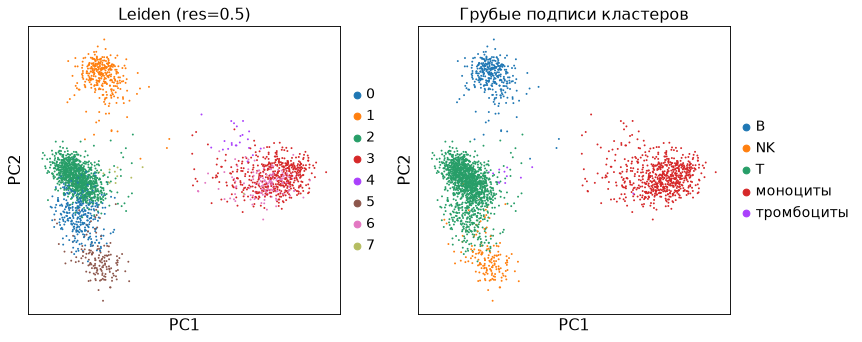

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sc.pl.pca(adata, color="leiden", ax=axes[0], show=False, size=12, title="Leiden (res=0.5)")
sc.pl.pca(adata, color="rough_type", ax=axes[1], show=False, size=12, title="Грубые подписи кластеров")
plt.tight_layout(); plt.show()

---
## Подумайте

### 1. Что сейчас лежит в слоях AnnData?

In [19]:
print("Слои:", list(adata.layers.keys()))
cells, genes = adata.obs_names[:4], ["LYZ", "CD74", "MALAT1", "NKG7"]
gi = adata.var_names.get_indexer(genes)
print("\nlayers['counts'] — сырые UMI:")
display(pd.DataFrame(adata.layers["counts"][:4][:, gi].toarray(), index=cells, columns=genes))
print("X — log1p(UMI / сумма UMI клетки × 10 000):")
display(pd.DataFrame(adata.X[:4][:, gi].toarray(), index=cells, columns=genes).round(3))

per_cell_counts = np.asarray(adata.layers["counts"].sum(axis=1)).ravel()
per_cell_norm = np.asarray(adata.X.expm1().sum(axis=1)).ravel()
print("Сумма UMI на клетку в counts:", per_cell_counts[:4], "...")
print("Сумма expm1(X) на клетку:     ", per_cell_norm[:4].round(1), "... (у всех клеток 10 000)")

Слои: ['counts']

layers['counts'] — сырые UMI:


,LYZ,CD74,MALAT1,NKG7
AAACATACAACCAC-1,1.0,1.0,49.0,0.0
AAACATTGAGCTAC-1,3.0,51.0,142.0,1.0
AAACATTGATCAGC-1,2.0,2.0,171.0,0.0
AAACCGTGCTTCCG-1,24.0,14.0,11.0,1.0


X — log1p(UMI / сумма UMI клетки × 10 000):


,LYZ,CD74,MALAT1,NKG7
AAACATACAACCAC-1,1.636,1.636,5.316,0.000
AAACATTGAGCTAC-1,1.963,4.654,5.672,1.112
AAACATTGATCAGC-1,1.995,1.995,6.300,0.000
AAACCGTGCTTCCG-1,4.521,3.990,3.754,1.566


Сумма UMI на клетку в counts: [2419. 4903. 3147. 2639.] ...
Сумма expm1(X) на клетку:      [10000. 10000. 10000. 10000.] ... (у всех клеток 10 000)


**Ответ.** Слой один — `counts`. Это копия **сырых целочисленных UMI**, сделанная до `normalize_total` и `log1p`. В `adata.X` теперь лежит $\log(1 + 10^4\cdot Y_{cg}/\sum_g Y_{cg})$: глубина секвенирования уравнена (сумма `expm1(X)` по клетке равна 10 000), а сильно экспрессируемые гены сжаты логарифмом. Слой `counts` нужен методам, которые работают с сырыми числами: HVG `seurat_v3` и `pearson_residuals`, scVI, DE на псевдобалках и т.п. Остальные новые поля — не слои: `obs` (QC-метрики), `var` (`highly_variable`, `means`, `variances`, `variances_norm`), `obsm["X_pca"]`, `varm["PCs"]`, `uns["pca"]`, `uns["log1p"]`, `uns["hvg"]`.

### 2. По каким генам ещё можно делать QC?

- **рибосомные белки** (RPL/RPS);
- **гемоглобины** (примесь эритроцитов);
- **гены тромбоцитов** (PPBP, PF4);
- **MALAT1** (ядерная lncRNA: если её почти нет, у «клетки» может не быть ядра);
- **гены стресса/диссоциации** (FOS, JUN, HSP).

Кроме того, используют долю UMI в топ-50 генах, «сложность» библиотеки $\log_{10}(n_{genes})/\log_{10}(n_{UMI})$, а также отдельные инструменты: оценку дублетов (Scrublet, scDblFinder) и фоновой («ambient») РНК (SoupX, CellBender).

### 3–4. Поиск по названию или по GTF/GFF? Сколько генов на митохондриальной хромосоме?

In [20]:
vn = raw.var_names
mt_hyphen = vn[vn.str.startswith("MT-")]
mt_no_hyphen = vn[vn.str.startswith("MT") & ~vn.str.startswith("MT-")]
print(f"Генов 'MT-' в матрице: {len(mt_hyphen)} ->", list(mt_hyphen))
print(f"\nНачинаются на 'MT' без дефиса: {len(mt_no_hyphen)} (это ЯДЕРНЫЕ гены), например:",
      [g for g in mt_no_hyphen if g.startswith(("MTRNR2L", "MT1", "MT2", "MTOR", "MTHFR"))][:12])
mrp = vn[vn.str.match(r"^MRP[SL]\d")]
print(f"\nЯдерные гены митохондриальных рибосомных белков MRPL/MRPS: {len(mrp)} (в 'MT-' не входят)")

ribo_loose = vn[vn.str.startswith(("RPS", "RPL"))]
ribo_strict = vn[vn.str.match(RIBO_REGEX)]
print(f"\nРибосомные: startswith('RPS','RPL') = {len(ribo_loose)}, строгое выражение = {len(ribo_strict)}")
print("Лишнее при простом поиске:", sorted(set(ribo_loose) - set(ribo_strict)))

Генов 'MT-' в матрице: 13 -> ['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']

Начинаются на 'MT' без дефиса: 92 (это ЯДЕРНЫЕ гены), например: ['MTOR', 'MTOR-AS1', 'MTHFR', 'MT1HL1', 'MTRNR2L11', 'MTRNR2L12', 'MTRNR2L13', 'MTRNR2L2', 'MTRNR2L9', 'MTRNR2L6', 'MTRNR2L10', 'MTRNR2L7']

Ядерные гены митохондриальных рибосомных белков MRPL/MRPS: 79 (в 'MT-' не входят)

Рибосомные: startswith('RPS','RPL') = 106, строгое выражение = 88
Лишнее при простом поиске: ['RPL17-C18orf32', 'RPL34-AS1', 'RPL36A-HNRNPH2', 'RPS10-NUDT3', 'RPS10P7', 'RPS19BP1', 'RPS6KA1', 'RPS6KA2', 'RPS6KA2-AS1', 'RPS6KA3', 'RPS6KA4', 'RPS6KA5', 'RPS6KA6', 'RPS6KB1', 'RPS6KB2', 'RPS6KC1', 'RPS6KL1', 'RPSAP58']


**Ответ.**

- **Сколько генов.** Митохондриальная ДНК человека кодирует **37 генов**: 13 белков дыхательной цепи, 22 тРНК и 2 рРНК. В матрице 10x (референс hg19) их только **13**: это белок-кодирующие гены `MT-ND1…6`, `MT-ND4L`, `MT-CO1…3`, `MT-ATP6/8`, `MT-CYB`. тРНК и рРНК в этой аннотации нет, к тому же они плохо ловятся poly(A)-захватом. Поэтому `pct_counts_mt` здесь — доля UMI именно с этих 13 генов.
- **Все ли начинаются с MT?** У человека все гены мтДНК начинаются с `MT-` **с дефисом**. Но на `MT` без дефиса начинаются и **ядерные** гены: `MTOR`, `MTHFR`, металлотионеины `MT1*`/`MT2A`, «гуманин-подобные» `MTRNR2L*`. Поиск по `startswith("MT")` смешал бы их с мтДНК. Обратная проблема: ядерные гены митохондриальных белков (`MRPL*/MRPS*`, субъединицы `NDUF*`, `COX*`) в мтДНК-группу не попадают, и так и должно быть.
- **Названия или GTF.** Надёжнее брать гены из **GTF/GFF той же аннотации, по которой строилась матрица**. Митохондриальные — по хромосоме (`MT`/`chrM`); рибосомные, гемоглобины и т.п. — по ID и типу гена (`gene_biotype`/`gene_type`). Поиск по названию зависит от номенклатуры вида и версии аннотации. Он ловит лишнее (`RPS6KA*` — это киназы, а не рибосомные белки; `HBEGF`, `HBP1` — не гемоглобины) и пропускает гены без символа (часть генов остаётся только с ID `ENSG…`). Названия удобны для быстрой проверки, а для итогового анализа лучше GTF.

### 5. Как называются митохондриальные гены у других организмов?
Это зависит от **вида и базы аннотации**. Примеры по NCBI Gene:
- **человек:** `MT-ND1` (HGNC);
- **мышь:** `mt-Nd1`;
- **крыса:** `Mt-nd1`;
- **данио рерио:** `mt-nd1`;
- **сабака и обезьян:** `MT-ND1` (номенклатура VGNC, как у человека);
- **корова, свинья, лошадь, макака:** без префикса — `ND1`, `COX1`, `ATP6`, `CYTB`;
- **дрозофила:** во FlyBase `mt:ND1`, `mt:CoI`.

Даже для одного вида префикс может отличаться между Ensembl, RefSeq и разными версиями сборки. Поэтому для «неклассических» организмов (корова, собака, курица, приматы) митохондриальные гены лучше определять по хромосоме `MT` в GTF, а не по префиксу.

---
## Задание 1. QC по дополнительным группам генов

QC смотрим **до** фильтрации (на всех 2700 клетках): задача — найти подозрительные клетки.

### 1.1. Группы генов и доля UMI

In [25]:
groups_table = pd.DataFrame({
    "что это": list(QC_GROUPS.values()),
    "число генов": [int(raw.var[g].sum()) for g in QC_GROUPS],
    "гены (первые 8)": [", ".join(raw.var_names[raw.var[g].values][:8]) for g in QC_GROUPS],
}, index=list(QC_GROUPS))
display(groups_table)

# Проверка формулы: доля UMI группы = 100 * UMI генов группы / все UMI клетки
X = raw.X.tocsr()
total = np.asarray(X.sum(axis=1)).ravel()
for g in QC_GROUPS:
    manual = 100 * np.asarray(X[:, raw.var[g].values].sum(axis=1)).ravel() / total
    assert np.allclose(manual, raw.obs[f"pct_counts_{g}"], atol=1e-3)
print("Ручной расчёт долей совпадает с sc.pp.calculate_qc_metrics")

QC_METRICS = ["n_genes_by_counts", "total_counts", "pct_counts_in_top_50_genes", "complexity"] + \
             [f"pct_counts_{g}" for g in QC_GROUPS]
THRESHOLDS = {"n_genes_by_counts": [200, 2500], "pct_counts_mt": [5]}   # пороги семинара
raw.obs[QC_METRICS].describe().T.round(3)

,что это,число генов,гены (первые 8)
mt,"митохондриальные гены (мтДНК, MT-)",13,"MT-ND1, MT-ND2, MT-CO1, MT-CO2, MT-ATP8, MT-AT..."
ribo,рибосомные белки (RPL/RPS),88,"RPL22, RPL11, RPS8, RPL5, RPS27, RPS7, RPS27A,..."
hb,гемоглобины (эритроциты),10,"HBB, HBD, HBG1, HBG2, HBE1, HBZ, HBM, HBA2"
platelet,"гены тромбоцитов (PPBP, PF4, ...)",8,"GP9, PF4V1, PF4, PPBP, SPARC, GNG11, ITGA2B, T..."
malat1,MALAT1 — ядерная lncRNA,1,MALAT1
stress,"гены стресса/диссоциации (FOS, JUN, HSPA1A, ...)",13,"JUN, ATF3, EGR1, DUSP1, IER3, HSPA1A, HSPA1B, FOS"


Ручной расчёт долей совпадает с sc.pp.calculate_qc_metrics


,count,mean,std,min,25%,50%,75%,max
n_genes_by_counts,2700.0,846.994,282.105,212.000,690.000,817.000,953.250,3422.000
total_counts,2700.0,2366.900,1094.262,548.000,1757.750,2197.000,2763.000,15844.000
pct_counts_in_top_50_genes,2700.0,43.992,4.720,28.420,40.813,44.112,47.147,69.913
complexity,2700.0,0.872,0.015,0.827,0.861,0.870,0.881,0.931
pct_counts_mt,2700.0,2.215,1.165,0.000,1.536,2.030,2.640,22.569
pct_counts_ribo,2700.0,34.848,10.192,1.056,26.300,36.653,43.224,59.113
pct_counts_hb,2700.0,0.002,0.032,0.000,0.000,0.000,0.000,1.363
pct_counts_platelet,2700.0,0.048,0.665,0.000,0.000,0.000,0.000,14.934
pct_counts_malat1,2700.0,2.806,1.796,0.000,1.555,2.591,3.636,17.511
pct_counts_stress,2700.0,1.064,0.609,0.000,0.628,1.013,1.405,5.294


### 1.2. Violin plots для всех QC-метрик

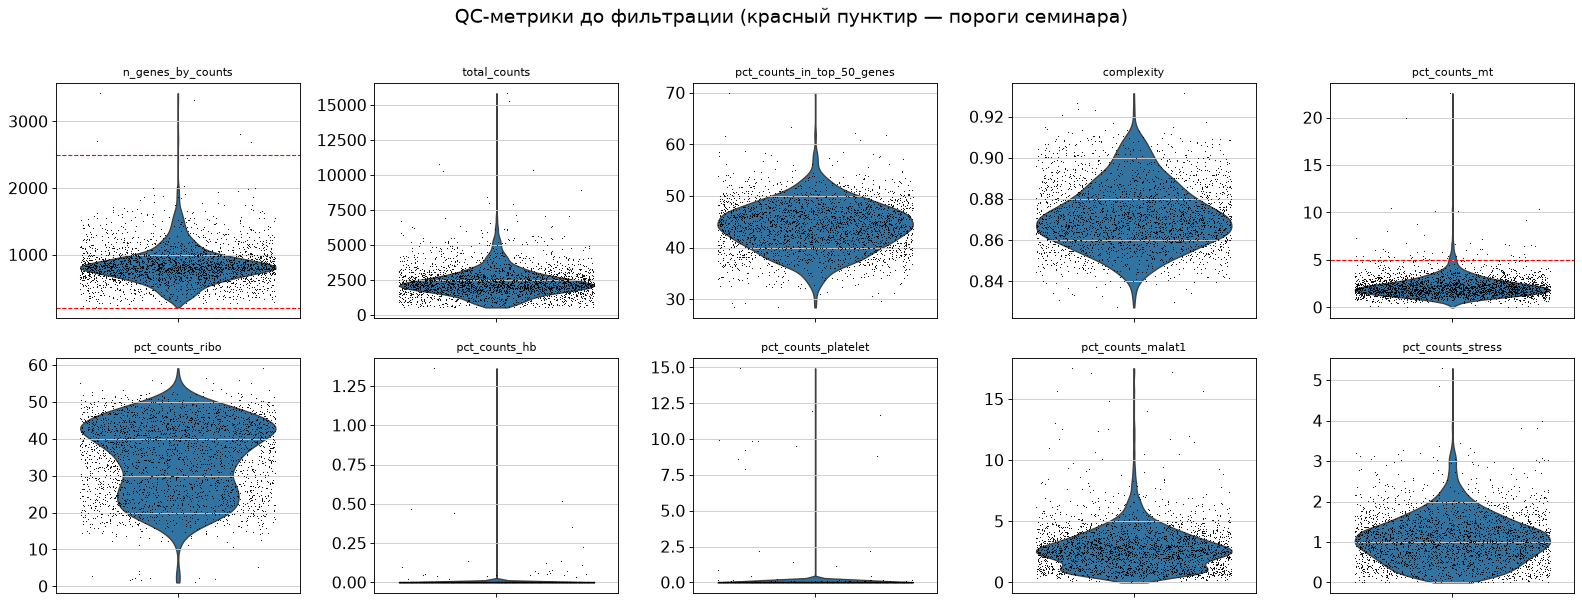

In [26]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, m in zip(axes.ravel(), QC_METRICS):
    sc.pl.violin(raw, keys=m, jitter=0.4, size=1, ax=ax, show=False)
    for t in THRESHOLDS.get(m, []):
        ax.axhline(t, color="red", ls="--", lw=1)
    ax.set_title(m, fontsize=10)
    ax.set_xticklabels([]); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("QC-метрики до фильтрации (красный пунктир — пороги семинара)", y=1.01)
plt.tight_layout(); plt.show()

### 1.3. Гистограммы (X — значение метрики, Y — число клеток)

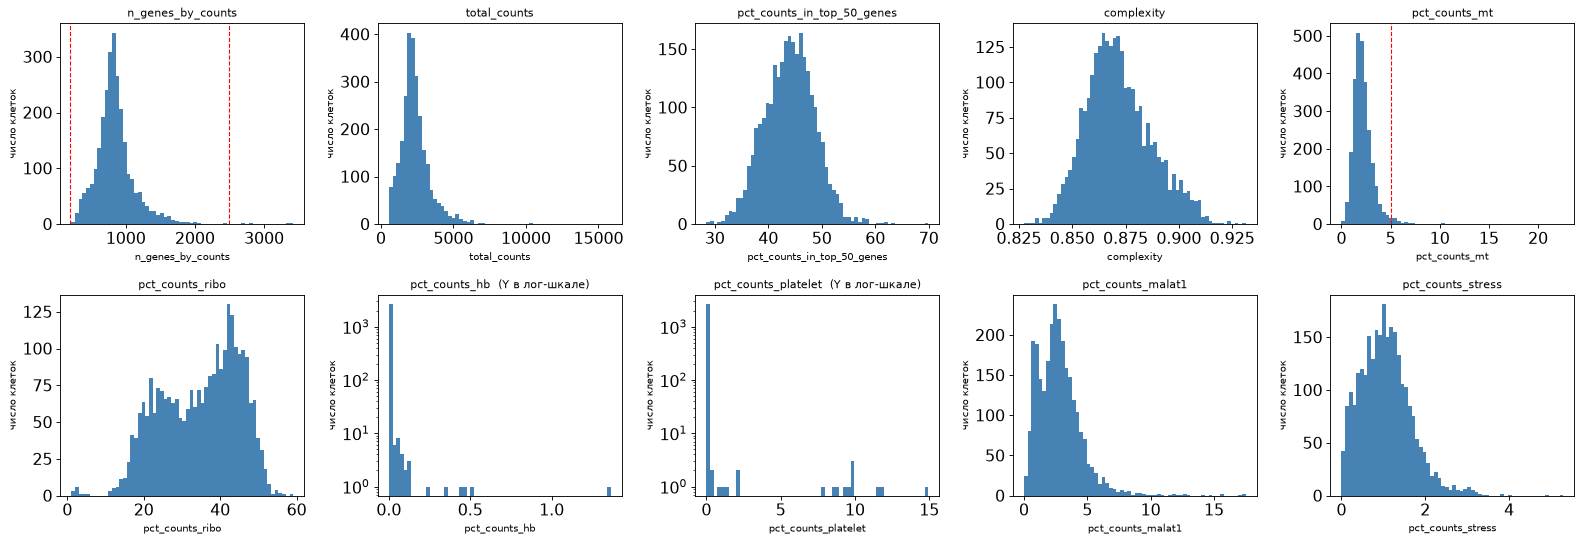

In [27]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, m in zip(axes.ravel(), QC_METRICS):
    ax.hist(raw.obs[m], bins=60, color="steelblue", edgecolor="none")
    for t in THRESHOLDS.get(m, []):
        ax.axvline(t, color="red", ls="--", lw=1)
    if m in ("pct_counts_hb", "pct_counts_platelet"):   # почти все клетки = 0, поэтому лог-шкала по Y
        ax.set_yscale("log")
        ax.set_title(m + "  (Y в лог-шкале)", fontsize=10)
    else:
        ax.set_title(m, fontsize=10)
    ax.set_xlabel(m, fontsize=9); ax.set_ylabel("число клеток", fontsize=9)
    ax.grid(False)
plt.tight_layout(); plt.show()

### 1.4. Scatter: число генов vs общее число UMI, окраска по каждой доле

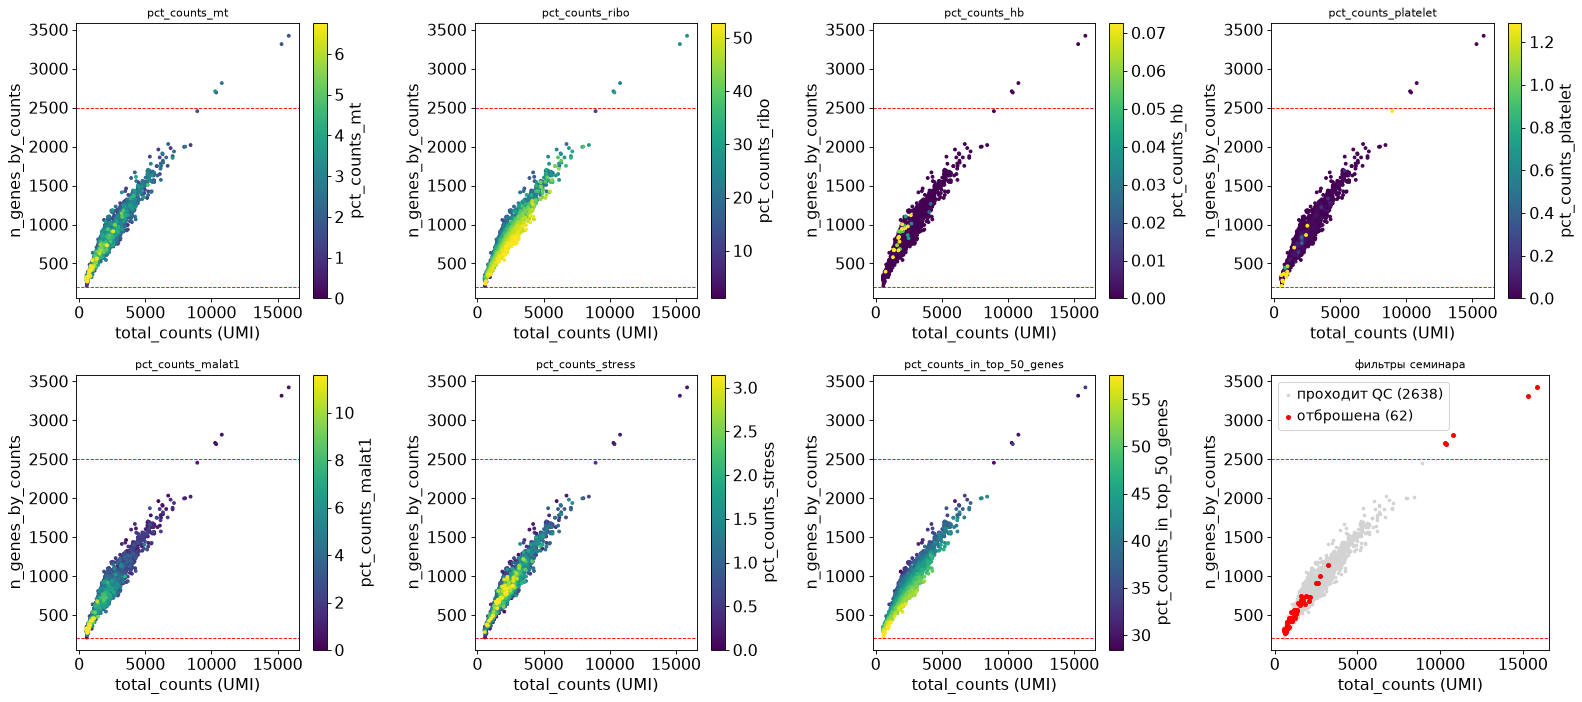

In [28]:
passed = raw.obs_names.isin(adata.obs_names)
color_by = [f"pct_counts_{g}" for g in QC_GROUPS] + ["pct_counts_in_top_50_genes"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, m in zip(axes.ravel(), color_by):
    order = np.argsort(raw.obs[m].values)          # клетки с большими значениями рисуем сверху
    s = ax.scatter(raw.obs["total_counts"].values[order], raw.obs["n_genes_by_counts"].values[order],
                   c=raw.obs[m].values[order], s=6, cmap="viridis",
                   vmax=np.percentile(raw.obs[m], 99.5) if raw.obs[m].max() > 0 else None)
    plt.colorbar(s, ax=ax, label=m)
    ax.set_title(m, fontsize=10)
ax = axes.ravel()[-1]
ax.scatter(raw.obs.loc[passed, "total_counts"], raw.obs.loc[passed, "n_genes_by_counts"], s=5, c="lightgrey",
           label=f"проходит QC ({passed.sum()})")
ax.scatter(raw.obs.loc[~passed, "total_counts"], raw.obs.loc[~passed, "n_genes_by_counts"], s=12, c="red",
           label=f"отброшена ({(~passed).sum()})")
ax.legend(); ax.set_title("фильтры семинара", fontsize=10)
for ax in axes.ravel():
    ax.axhline(2500, color="red", ls="--", lw=0.8); ax.axhline(200, color="red", ls="--", lw=0.8)
    ax.set_xlabel("total_counts (UMI)"); ax.set_ylabel("n_genes_by_counts"); ax.grid(False)
plt.tight_layout(); plt.show()

### 1.5. Какие клетки подозрительны: сводка по критериям

Кроме фиксированных порогов семинара используем **адаптивные** пороги через MAD — медианное абсолютное отклонение (подход из *sc-best-practices*): выброс — это клетка дальше чем на $k$ MAD от медианы.

In [29]:
def mad_bounds(x, k):
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    return med - k * mad, med + k * mad

o = raw.obs
lt_lo, lt_hi = mad_bounds(np.log1p(o["total_counts"]), 5)
lg_lo, lg_hi = mad_bounds(np.log1p(o["n_genes_by_counts"]), 5)
_, mt_hi = mad_bounds(o["pct_counts_mt"], 3)
_, top_hi = mad_bounds(o["pct_counts_in_top_50_genes"], 5)
_, st_hi = mad_bounds(o["pct_counts_stress"], 5)

flags = pd.DataFrame({
    "мало UMI (< −5 MAD, log)": np.log1p(o["total_counts"]) < lt_lo,
    "много UMI (> +5 MAD, log)": np.log1p(o["total_counts"]) > lt_hi,
    "мало генов (< −5 MAD, log)": np.log1p(o["n_genes_by_counts"]) < lg_lo,
    "много генов (> +5 MAD, log)": np.log1p(o["n_genes_by_counts"]) > lg_hi,
    "≥ 2500 генов (порог семинара)": o["n_genes_by_counts"] >= 2500,
    f"mt > медиана + 3 MAD (> {mt_hi:.2f}%)": o["pct_counts_mt"] > mt_hi,
    "mt ≥ 5% (порог семинара)": o["pct_counts_mt"] >= 5,
    "топ-50 генов > +5 MAD": o["pct_counts_in_top_50_genes"] > top_hi,
    "тромбоцитарные > 1%": o["pct_counts_platelet"] > 1,
    "гемоглобин > 1%": o["pct_counts_hb"] > 1,
    "MALAT1 < 0.5%": o["pct_counts_malat1"] < 0.5,
    "стресс > +5 MAD": o["pct_counts_stress"] > st_hi,
    "complexity < 0.8": o["complexity"] < 0.8,
}, index=o.index)

summary = pd.DataFrame({
    "клеток": flags.sum(),
    "из них отброшены фильтрами семинара": flags[~passed].sum(),
})
for m in ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_malat1"]:
    summary[f"медиана {m}"] = [o.loc[flags[c], m].median() if flags[c].any() else np.nan for c in flags]
display(summary.round(2))
print("Медианы по всем клеткам:", o[["total_counts", "n_genes_by_counts", "pct_counts_mt",
                                     "pct_counts_ribo", "pct_counts_malat1"]].median().round(2).to_dict())

,клеток,из них отброшены фильтрами семинара,медиана total_counts,медиана n_genes_by_counts,медиана pct_counts_mt,медиана pct_counts_ribo,медиана pct_counts_malat1
"мало UMI (< −5 MAD, log)",45,11,642.0,324.0,3.02,26.41,2.93
"много UMI (> +5 MAD, log)",13,5,8424.0,2020.0,1.76,27.37,0.84
"мало генов (< −5 MAD, log)",59,15,663.0,331.0,2.95,27.88,2.49
"много генов (> +5 MAD, log)",20,5,7120.5,1989.0,1.76,27.11,0.73
≥ 2500 генов (порог семинара),5,5,10783.0,2815.0,1.79,26.51,0.50
mt > медиана + 3 MAD (> 3.65%),202,57,1621.5,654.5,4.32,32.50,2.85
mt ≥ 5% (порог семинара),57,57,1025.0,462.0,5.85,30.54,4.11
топ-50 генов > +5 MAD,6,0,636.5,256.5,0.99,2.26,0.31
тромбоцитарные > 1%,15,0,947.0,364.0,2.75,2.26,0.17
гемоглобин > 1%,1,0,1981.0,944.0,2.32,19.28,3.18


Медианы по всем клеткам: {'total_counts': 2197.0, 'n_genes_by_counts': 817.0, 'pct_counts_mt': 2.03, 'pct_counts_ribo': 36.65, 'pct_counts_malat1': 2.59}


### 1.6. Высокая доля группы генов — не всегда «плохая» клетка

Сравним QC-метрики между грубыми популяциями (после фильтрации).

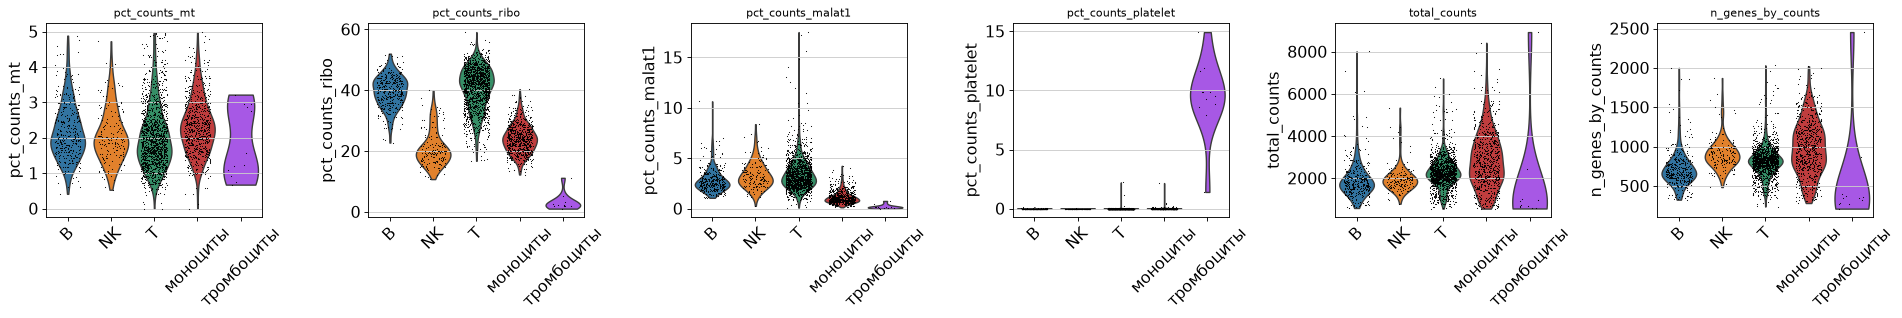

,pct_counts_mt,pct_counts_ribo,pct_counts_malat1,pct_counts_platelet,total_counts,n_genes_by_counts
rough_type,,,,,,
B,2.05,39.919998,2.56,0.00,1764.0,675.5
NK,1.95,19.510000,3.03,0.00,1915.0,890.0
T,1.86,41.900002,3.15,0.00,2250.0,814.0
моноциты,2.27,23.889999,1.00,0.00,2733.0,970.5
тромбоциты,1.40,2.230000,0.15,9.67,827.0,348.0


In [30]:
qc_by_type = ["pct_counts_mt", "pct_counts_ribo", "pct_counts_malat1", "pct_counts_platelet",
              "total_counts", "n_genes_by_counts"]
fig, axes = plt.subplots(1, len(qc_by_type), figsize=(24, 4.2))
for ax, m in zip(axes, qc_by_type):
    sc.pl.violin(adata, keys=m, groupby="rough_type", ax=ax, show=False, jitter=0.3, size=1, rotation=45)
    ax.set_title(m, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()
adata.obs.groupby("rough_type", observed=True)[qc_by_type].median().round(2)

**Ответы на вопросы задания 1**

**Какие клетки выглядят подозрительными?**
- **Повреждённые и умирающие.** У них высокая доля митохондриальных UMI. Выше 5% таких клеток 57, максимум 22.6%. Обычно у них одновременно мало UMI и генов: цитоплазматическая мРНК вытекла через разрушенную мембрану, а митохондрии, окружённые мембраной, остались. Адаптивный порог (медиана + 3 MAD ≈ 3.65%) строже: он помечает около 200 клеток. Это в основном нормальные клетки с хвоста распределения, поэтому для PBMC порог 5% разумнее.
- **Возможные дублеты.** Это клетки с аномально большим числом генов и UMI. Порог семинара (≥ 2500 генов) отсекает 5 клеток (до 3422 генов и 15 844 UMI). Адаптивный порог (+5 MAD по числу генов) помечает 20 клеток, у них медиана ≈ 2000 генов и ≈ 7100 UMI при общей медиане 817 и 2197. Они лежат в правом верхнем углу scatter plot. Точнее дублеты находят специальные инструменты (Scrublet, scDblFinder).
- **Клетки с маленькой библиотекой** (−5 MAD: 45 клеток по UMI, 59 по генам). Это или плохой захват, или биологически маленькие «клетки» (см. тромбоциты ниже).
- **Тромбоциты** — 12–15 «клеток» с долей PPBP/PF4 от 1 до 15%. У них мало генов (медиана ≈ 350), почти нет рибосомных UMI (≈ 2%) и почти нет MALAT1 (≈ 0.15%). Оч. Четыре из них попали и в 6 выбросов по доле UMI в топ-50 генах: их транскриптом состоит из немногих генов (`PPBP`, `PF4`, ...). Ещё два таких выброса — «клетки» примерно с 240 генами, у которых ≈ 57–59% UMI приходится на рибосомные белки: это кандидаты на фрагменты клеток или плохой захват. Порогами семинара они не удаляются. Это реальная популяция, хотя и низкого «качества» по формальным метрикам. Часть таких событий может быть и дублетами «клетка + тромбоцит».
- **MALAT1 < 0.5%** у 70 клеток, но это почти не «плохие» клетки: из 66 прошедших QC 49 — моноциты (у моноцитов медиана MALAT1 ≈ 1% против ≈ 3% у лимфоцитов) и 11 — тромбоциты.
- **Гемоглобин** практически отсутствует: максимум 1.4%, только у одной клетки больше 1%. Эритроциты удалены при выделении PBMC (градиент фиколла), примеси эритроцитов нет.
- **Гены стресса**: выбросов немного (29 клеток выше +5 MAD, максимум 5.3%), сильной сигнатуры диссоциации нет. «Сложность» у всех клеток выше 0.82, клеток-«пустышек» с несколькими доминирующими транскриптами нет.

**Какие метрики говорят о низком качестве?** Совокупность признаков, а не одна метрика:
- мало UMI и генов вместе с высокой долей мтДНК (разрушенная клетка);
- высокая доля UMI в топ-50 генах и низкая «сложность» (пустая капля, фоновая РНК);
- аномально много UMI и генов (дублет);
- очень мало MALAT1 (нет ядра или фрагмент цитоплазмы) — но только с поправкой на тип клетки, у моноцитов MALAT1 и так низкий; очень много MALAT1 при малом числе генов — «голое» ядро без цитоплазмы.

**Почему высокая доля группы генов не всегда означает плохое качество?** Доли зависят от **типа и состояния клетки**:
- **Рибосомные UMI** в нашем случае: медиана ≈ 42% у T-клеток, ≈ 40% у B, ≈ 20% у NK, ≈ 24% у моноцитов и ≈ 2% у тромбоцитов. Это биология (покоящиеся T- и B-лимфоциты с маленькой цитоплазмой), а не дефект. Порог по рибосомным генам вырезал бы целые популяции.
- **Доля мтДНК** выше у метаболически активных клеток: у моноцитов здесь немного выше, чем у T-клеток. В тканях эффект ещё сильнее: у кардиомиоцитов, гепатоцитов и клеток почечных канальцев нормальная доля мтДНК бывает 20–50%.
- **Гемоглобин** в крови или костном мозге может означать настоящие эритроидные клетки (ретикулоциты, эритробласты), а не примесь.
- **Гены тромбоцитов** — маркер настоящей популяции тромбоцитов и мегакариоцитов.
- **Гены стресса** (FOS, JUN) бывают биологическим ответом *in vivo*, например при активации.

Поэтому пороги лучше выбирать адаптивно (MAD, отдельно для каждого образца), смотреть на сочетание метрик и проверять, не совпадают ли «плохие» клетки с целым кластером.

---
## Задание 2. Сравнение методов отбора HVG

Три набора по 2000 генов:
- `seurat_v3` (как на семинаре): дисперсия сырых counts, стандартизованная через подгонку среднее–дисперсия (loess);
- `seurat`: нормированная дисперсия лог-данных внутри бинов по среднему;
- `pearson_residuals` (`sc.experimental.pp.highly_variable_genes`): дисперсия остатков Пирсона модели NB с поправкой на глубину.

PCA для **всех** методов строим на **одной и той же** матрице `adata.X` (normalize + log1p). Меняется только маска генов.

In [31]:
hvg_sets = pd.DataFrame(index=adata.var_names)
hvg_sets["seurat_v3"] = adata.var["highly_variable"].values

df_seurat = sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000, inplace=False)  # на лог-данных
hvg_sets["seurat"] = df_seurat["highly_variable"].values

tmp = adata.copy()   # experimental-функция пишет результат в .var, поэтому работаем на копии
sc.experimental.pp.highly_variable_genes(tmp, flavor="pearson_residuals", n_top_genes=2000, layer="counts")
hvg_sets["pearson_residuals"] = tmp.var["highly_variable"].values
del tmp

methods = list(hvg_sets.columns)
print("Размеры наборов:", hvg_sets.sum().to_dict())

# Пересечения
inter = pd.DataFrame([[int((hvg_sets[a] & hvg_sets[b]).sum()) for b in methods] for a in methods],
                     index=methods, columns=methods)
print(f"\nВо всех трёх наборах одновременно: {int(hvg_sets.all(axis=1).sum())} генов")
print("\nПопарные пересечения (на диагонали — размер набора):")
display(inter)

# Насколько разные гены выбирает каждый метод
gene_mean = np.asarray(adata.layers["counts"].mean(axis=0)).ravel()
rows = {}
for m in methods:
    uniq = hvg_sets[m] & ~hvg_sets.drop(columns=m).any(axis=1)
    rows[m] = {
        "медиана среднего UMI в наборе": np.median(gene_mean[hvg_sets[m].values]),
        "уникальных генов": int(uniq.sum()),
        "рибосомных генов в наборе": int(adata.var.loc[hvg_sets[m].values, "ribo"].sum()),
        "рибосомных среди уникальных": int(adata.var.loc[uniq.values, "ribo"].sum()),
        "уникальные с наибольшей экспрессией": ", ".join(
            pd.Series(gene_mean[uniq.values], index=hvg_sets.index[uniq]).nlargest(8).index),
    }
display(pd.DataFrame(rows).T)
print("Маркеры в наборах HVG:")
display(hvg_sets.loc[MARKER_GENES])

Размеры наборов: {'seurat_v3': 2000, 'seurat': 2000, 'pearson_residuals': 2000}

Во всех трёх наборах одновременно: 1145 генов

Попарные пересечения (на диагонали — размер набора):


,seurat_v3,seurat,pearson_residuals
seurat_v3,2000,1505,1402
seurat,1505,2000,1291
pearson_residuals,1402,1291,2000


,медиана среднего UMI в наборе,уникальных генов,рибосомных генов в наборе,рибосомных среди уникальных,уникальные с наибольшей экспрессией
seurat_v3,0.070508,238,4,0,"RP11-290F20.3, EPC1, LILRB2, DUSP23, DNPH1, HM..."
seurat,0.056293,349,11,0,"JAGN1, SLC39A3, MFSD1, ELP5, DTYMK, YIPF5, PDZ..."
pearson_residuals,0.153336,452,69,57,"RPL10, RPL13A, RPS2, RPS6, RPS18, RPL11, RPL32..."


Маркеры в наборах HVG:


,seurat_v3,seurat,pearson_residuals
CD3D,False,False,True
MS4A1,True,True,True
NKG7,True,True,True
LST1,True,True,True


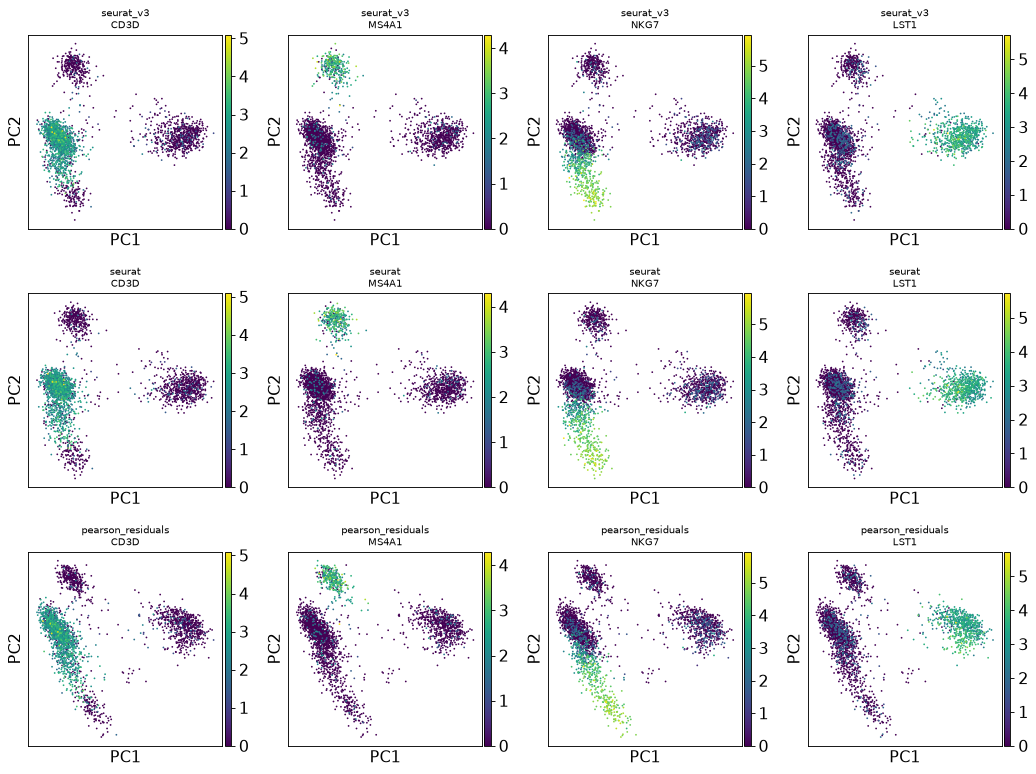

In [32]:
pca_hvg = {}
for m in methods:
    a = adata.copy()
    sc.tl.pca(a, n_comps=50, mask_var=hvg_sets[m].values, random_state=SEED)
    align_signs(a, adata)
    pca_hvg[m] = a

pca_grid(pca_hvg, MARKER_GENES)

,доля дисп. PC1,доля дисп. PC2,доля дисп. PC3,|r| PC1 с seurat_v3,|r| PC2 с seurat_v3,|r| PC3 с seurat_v3,ARI Leiden vs seurat_v3,число кластеров
seurat_v3,0.100,0.033,0.023,1.000,1.000,1.000,1.000,8.0
seurat,0.102,0.035,0.024,0.997,0.991,0.986,0.939,7.0
pearson_residuals,0.084,0.029,0.020,0.990,0.928,0.861,0.673,8.0


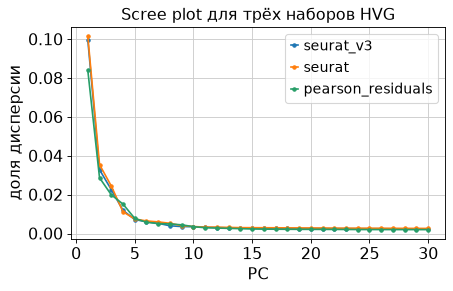

In [33]:
# Количественное сравнение: совпадение осей и кластеров
ref = pca_hvg["seurat_v3"]
rows = {}
for m, a in pca_hvg.items():
    add_leiden(a, key="leiden_hvg")
    rows[m] = {
        **{f"доля дисп. PC{i + 1}": a.uns["pca"]["variance_ratio"][i] for i in range(3)},
        **{f"|r| PC{i + 1} с seurat_v3": abs(np.corrcoef(a.obsm["X_pca"][:, i], ref.obsm["X_pca"][:, i])[0, 1])
           for i in range(3)},
        "ARI Leiden vs seurat_v3": adjusted_rand_score(adata.obs["leiden"], a.obs["leiden_hvg"]),
        "число кластеров": a.obs["leiden_hvg"].nunique(),
    }
display(pd.DataFrame(rows).T.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
for m, a in pca_hvg.items():
    ax.plot(range(1, 31), a.uns["pca"]["variance_ratio"][:30], marker="o", ms=3, label=m)
ax.set(xlabel="PC", ylabel="доля дисперсии", title="Scree plot для трёх наборов HVG"); ax.legend()
plt.show()

**Ответы**

**Насколько отличаются расположения клеток?** На уровне первых компонент почти не отличаются.
- **`seurat`** практически совпадает с `seurat_v3`: |r| для PC1–PC3 ≈ 0.99, кластеры Leiden почти те же (ARI ≈ 0.94).
- **`pearson_residuals`** отличается сильнее: PC1 совпадает (|r| ≈ 0.99), PC2 — с |r| ≈ 0.93, PC3 — только ≈ 0.86. Доля дисперсии PC1 у него меньше (≈ 8% против ≈ 10%), а кластеры Leiden согласуются умеренно (ARI ≈ 0.68): крупные популяции те же, но мелкие кластеры нарезаны по-другому.
- Причина — **разный состав генов**. `seurat` охотнее берёт слабо экспрессируемые гены (медиана среднего ≈ 0.06 UMI на клетку). `pearson_residuals` — более экспрессируемые (≈ 0.15), в том числе рибосомные белки: модель с поправкой только на глубину считает их различия между лимфоцитами и моноцитами биологическими.

Знак компонент произволен: без выравнивания картинки могли бы оказаться зеркальными, и это не было бы различием.

**Сохраняются ли группы клеток с характерной экспрессией маркеров?** Да, во всех трёх вариантах. Моноциты (`LST1`) уходят вдоль PC1, B-клетки (`MS4A1`) и NK (`NKG7`) расходятся вдоль PC2 в противоположные стороны, T-клетки (`CD3D`) лежат в общем лимфоидном «облаке». Интересная деталь: `CD3D` **не попал** в HVG ни `seurat_v3`, ни `seurat` (попал только в `pearson_residuals`), но окраска по нему всё равно работает. Цвет берётся из полной матрицы, а T-клетки отделяются от остальных по другим генам (`LTB`, `IL32`, `IL7R`, ...).

**Сколько генов попало в оба набора HVG?** `seurat_v3` ∩ `seurat` = **1505** из 2000 (≈ 75%). `seurat_v3` ∩ `pearson_residuals` = 1402, `seurat` ∩ `pearson_residuals` = 1291, во всех трёх сразу — 1145. Ядро сильных генов общее, а около четверти генов у разных методов разные. В основном это гены «на границе» отбора: на PC1–PC2 они почти не влияют, но меняют более поздние компоненты и мелкие кластеры.

---
## Задание 3. PCA без отбора HVG

Та же матрица `adata.X` (normalize + log1p, без scale). PCA на **всех 13 714 генах** после QC против PCA на 2000 HVG.

Генов в PCA: 13714 против 2000


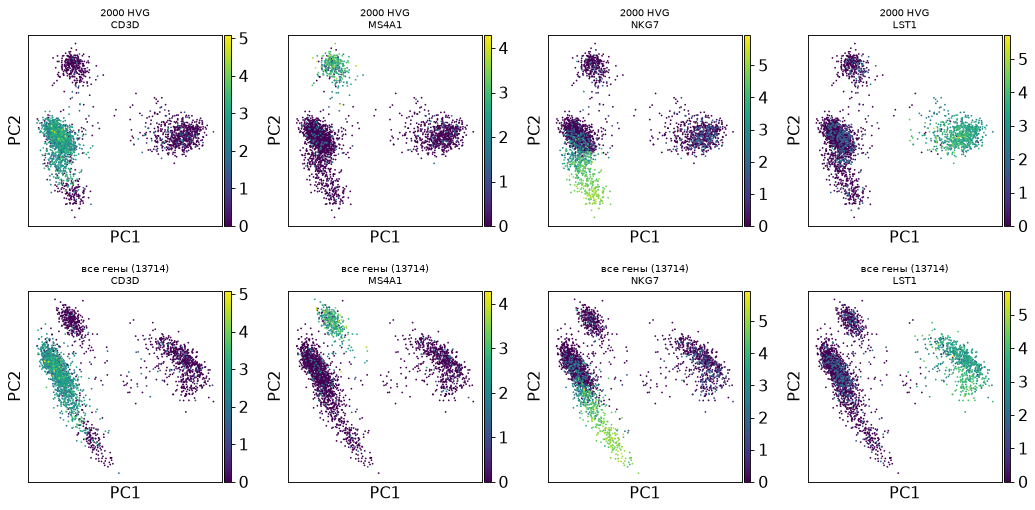

In [34]:
adata_all = adata.copy()
sc.tl.pca(adata_all, n_comps=50, mask_var=None, random_state=SEED)   # mask_var=None → все гены
align_signs(adata_all, adata)
print("Генов в PCA:", adata_all.varm["PCs"].shape[0], "против", int(adata.var["highly_variable"].sum()))

pca_cmp = {"2000 HVG": adata, f"все гены ({adata.n_vars})": adata_all}
pca_grid(pca_cmp, MARKER_GENES)

Суммарная дисперсия: все гены = 1954, HVG = 539 (28% от общей при 15% генов)


,2000 HVG,все гены (13714)
доля дисп. PC1,0.100000,0.046000
доля дисп. PC2,0.033000,0.016000
доля дисп. PC1–10,0.197000,0.100000
доля дисп. PC1–50,0.293000,0.150000
абс. дисперсия PC1,53.772999,89.552002
абс. дисперсия PC2,17.686001,31.275999


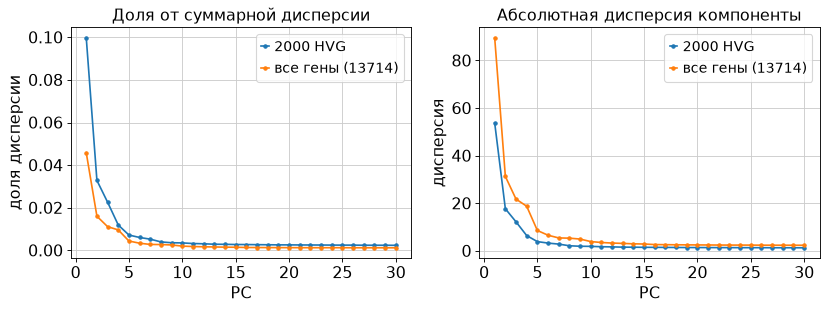

|r| между PC (строки — все гены, столбцы — HVG):


,PC1 HVG,PC2 HVG,PC3 HVG,PC4 HVG,PC5 HVG
PC1 all,0.99,0.07,0.08,0.02,0.03
PC2 all,0.10,0.89,0.34,0.22,0.04
PC3 all,0.09,0.17,0.72,0.50,0.20
PC4 all,0.01,0.39,0.54,0.65,0.17
PC5 all,0.04,0.09,0.17,0.40,0.57


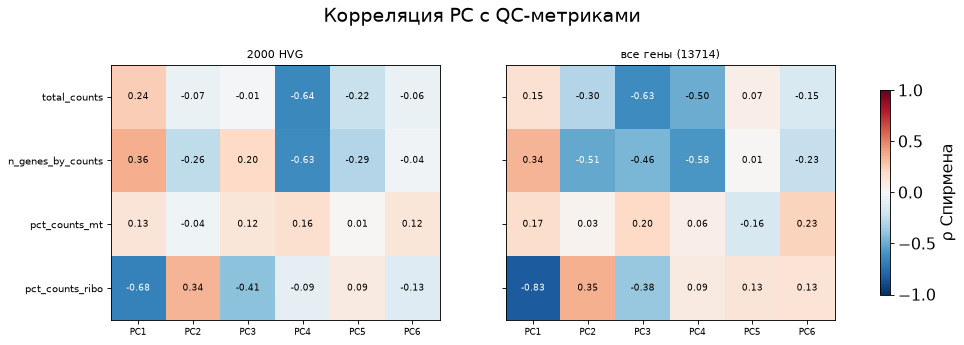

,топ-20 генов,рибосомных,не входят в HVG
PC1 «−» (лимфоидный полюс),"LTB, IL32, CD3D, PTPRCAP, RPS27A, LDHB, CD3E, RPSA, RPS3A, CXCR4, RPL9, MALAT1, RPS29, IL7R, RPS27, RPL31, RPSAP58, NPM1, RPL21, RPL23A",9,"CD3D, PTPRCAP, RPS27A, LDHB, CD3E, RPSA, RPS3A, CXCR4, RPL9, RPS29, RPS27, RPL31, RPSAP58, NPM1, RPL21, RPL23A"
PC1 «+» (миелоидный полюс),"LYZ, CST3, S100A9, TYROBP, LGALS1, S100A8, LST1, AIF1, FCER1G, FTL, FCN1, SAT1, HLA-DRA, CTSS, TYMP, COTL1, FTH1, S100A11, S100A4, PSAP",0,



ARI Leiden (все гены) vs Leiden (HVG): 0.677


In [35]:
gv = gene_variances(adata.X)
tot_all, tot_hvg = gv.sum(), gv[adata.var["highly_variable"].values].sum()
print(f"Суммарная дисперсия: все гены = {tot_all:.0f}, HVG = {tot_hvg:.0f} "
      f"({100 * tot_hvg / tot_all:.0f}% от общей при {100 * 2000 / adata.n_vars:.0f}% генов)")

cmp = pd.DataFrame({
    name: {
        "доля дисп. PC1": a.uns["pca"]["variance_ratio"][0],
        "доля дисп. PC2": a.uns["pca"]["variance_ratio"][1],
        "доля дисп. PC1–10": a.uns["pca"]["variance_ratio"][:10].sum(),
        "доля дисп. PC1–50": a.uns["pca"]["variance_ratio"].sum(),
        "абс. дисперсия PC1": a.uns["pca"]["variance"][0],
        "абс. дисперсия PC2": a.uns["pca"]["variance"][1],
    } for name, a in pca_cmp.items()
}).round(3)
display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, a in pca_cmp.items():
    axes[0].plot(range(1, 31), a.uns["pca"]["variance_ratio"][:30], marker="o", ms=3, label=name)
    axes[1].plot(range(1, 31), a.uns["pca"]["variance"][:30], marker="o", ms=3, label=name)
axes[0].set(xlabel="PC", ylabel="доля дисперсии", title="Доля от суммарной дисперсии")
axes[1].set(xlabel="PC", ylabel="дисперсия", title="Абсолютная дисперсия компоненты")
for ax in axes: ax.legend()
plt.show()

print("|r| между PC (строки — все гены, столбцы — HVG):")
display(pd.DataFrame([[abs(np.corrcoef(adata_all.obsm["X_pca"][:, i], adata.obsm["X_pca"][:, j])[0, 1])
                       for j in range(5)] for i in range(5)],
                     index=[f"PC{i + 1} all" for i in range(5)], columns=[f"PC{j + 1} HVG" for j in range(5)]).round(2))

qc_cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
corr_heatmaps({name: pc_corr(a, qc_cols, 6) for name, a in pca_cmp.items()},
              "Корреляция PC с QC-метриками")

load_all = pd.Series(adata_all.varm["PCs"][:, 0], index=adata_all.var_names)
poles = {}
for sign, genes in [("PC1 «−» (лимфоидный полюс)", load_all.nsmallest(20).index),
                    ("PC1 «+» (миелоидный полюс)", load_all.nlargest(20).index)]:
    poles[sign] = {"топ-20 генов": ", ".join(genes),
                   "рибосомных": int(adata.var.loc[genes, "ribo"].sum()),
                   "не входят в HVG": ", ".join(genes[~adata.var.loc[genes, "highly_variable"].values])}
with pd.option_context("display.max_colwidth", 200):
    display(pd.DataFrame(poles).T)

add_leiden(adata_all, key="leiden_all")
print("\nARI Leiden (все гены) vs Leiden (HVG):",
      round(adjusted_rand_score(adata.obs["leiden"], adata_all.obs["leiden_all"]), 3))

**Ответы**

**Как изменилась структура клеток?** Крупные оси те же: PC1 разделяет моноциты и лимфоциты (|r| ≈ 0.99 с PC1 по HVG), PC2 — B и NK (|r| ≈ 0.89). Дальше компоненты начинают «перемешиваться»: PC3 и PC4 по всем генам соответствуют смеси PC3/PC4 по HVG (|r| 0.5–0.7). На картинке PC1–PC2 облака более размытые, B-клетки и NK хуже отделены от T-клеток. Кластеры Leiden на графе из «всех генов» совпадают с эталонными лишь частично (ARI ≈ 0.68).

**Какие компоненты объясняют больше дисперсии?**
- **В долях** первые компоненты по HVG объясняют больше: PC1 ≈ 10% против ≈ 4.6%, PC1–10 ≈ 20% против ≈ 10%.
- **В абсолютных числах** компоненты по всем генам «длиннее», потому что к сумме добавились тысячи генов.
- Но эти тысячи генов несут в основном шум. 2000 HVG (15% генов) дают около 28% всей дисперсии, остальные 85% генов — около 72%, и эта дисперсия «размазана» по множеству мелких компонент.

**Почему все гены не делают PCA информативнее?**
1. Большинство генов экспрессируется слабо. Их дисперсия — пуассоновский или биномиальный шум выборки UMI, а не различия между типами клеток. PCA максимизирует **любую** дисперсию, поэтому шум «съедает» компоненты.
2. В PCA попадают гены с высокой, но не специфичной экспрессией. Из 20 генов лимфоидного полюса PC1 по всем генам 9 — рибосомные белки (`RPS27A`, `RPSA`, `RPS3A`, `RPL9`, ...), и ни один из них не входит в HVG. Поэтому PC1 сильнее коррелирует с долей рибосомных UMI (ρ ≈ −0.83 против −0.68). Там же появляются `CD3D`/`CD3E`: полезный сигнал среди не-HVG тоже есть, но на каждый такой ген приходятся сотни шумных.
3. Становятся заметнее технические оси: глубина секвенирования. PC3 по всем генам коррелирует с `total_counts` (ρ ≈ −0.63), а по HVG такая ось появляется только на PC4.
4. Это ещё и дольше и требует больше памяти.

HVG — это фильтр «сигнал/шум» перед PCA.

---
## Задание 4. HVG и уровень экспрессии

Статистики считаем по **сырым counts** (`layers["counts"]`) клеток после QC. Для каждого гена:
- среднее число UMI на клетку;
- дисперсия;
- индекс дисперсии (var/mean);
- стандартизованная дисперсия `seurat_v3` (`variances_norm`) — именно по ней ранжируются HVG;
- доля клеток, где ген обнаружен.

In [38]:
GENE_NOTES = {
    # высокоэкспрессируемые HVG
    "MALAT1": "ядерная lncRNA, регуляция сплайсинга; маркер ядерной фракции",
    "TMSB4X": "тимозин β4, связывает G-актин (цитоскелет)",
    "B2M": "β2-микроглобулин, лёгкая цепь MHC I",
    "FTL": "лёгкая цепь ферритина (хранение железа), высоко в моноцитах",
    "FTH1": "тяжёлая цепь ферритина",
    "ACTB": "β-актин, цитоскелет",
    "LYZ": "лизоцим — антибактериальный фермент моноцитов",
    "CD74": "инвариантная цепь MHC II (B-клетки, моноциты, DC)",
    "S100A4": "S100, Ca-связывающий; подвижность (T-памяти, NK, моноциты)",
    "MT-CO2": "мтДНК: субъединица II цитохром-c-оксидазы",
    "HLA-DRA": "α-цепь MHC II (DR)",
    "S100A9": "кальпротектин (с S100A8), воспаление; моноциты",
    "S100A8": "кальпротектин (с S100A9), воспаление; моноциты",
    "OAZ1": "антизим орнитиндекарбоксилазы, обмен полиаминов",
    "CST3": "цистатин C, ингибитор цистеиновых протеаз (моноциты, DC)",
    "S100A6": "S100 (калициклин)",
    "LTB": "лимфотоксин β (T- и B-лимфоциты)",
    "SH3BGRL3": "небольшой тиоредоксин-подобный белок, повсеместный",
    "VIM": "виментин, промежуточные филаменты",
    "TYROBP": "DAP12, адаптер активирующих рецепторов (NK, миелоидные)",
    "LGALS1": "галектин-1, иммунорегуляция (моноциты)",
    "COTL1": "coactosin-like 1, связывает F-актин",
    "HLA-DPB1": "β-цепь MHC II (DP)",
    "HLA-DPA1": "α-цепь MHC II (DP)",
    "HLA-DRB1": "β-цепь MHC II (DR)",
    "SAT1": "спермидин/спермин-N1-ацетилтрансфераза, катаболизм полиаминов",
    "NKG7": "белок цитотоксических гранул NK и CD8 T",
    "CD37": "тетраспанин, высоко на B-клетках",
    "IFITM2": "интерферон-индуцируемый трансмембранный белок, противовирусная защита",
    "AIF1": "AIF1/Iba1, моноциты и макрофаги",
    "ARPC1B": "субъединица комплекса Arp2/3 (полимеризация актина)",
    "LST1": "leukocyte specific transcript 1, моноциты (особенно FCGR3A+)",
    "IL32": "интерлейкин-32, T- и NK-клетки",
    "UBB": "убиквитин B",
    "FCER1G": "γ-цепь Fc-рецепторов (миелоидные, NK)",
    "CTSS": "катепсин S, процессинг антигенов (миелоидные)",
    "CCL5": "хемокин RANTES (CD8 T, NK)",
    "S100A11": "S100", "S100A10": "S100 (p11)",
    "SRGN": "серглицин, протеогликан секреторных гранул",
    "PSAP": "просапозин, лизосомальный белок (моноциты)",
    "GNLY": "гранулизин, цитотоксичность NK и CD8 T",
    "KLF6": "транскрипционный фактор KLF6",
    "ANXA1": "аннексин A1, противовоспалительный",
    "FCN1": "фиколин-1, лектиновый путь комплемента (классические моноциты)",
    "RBM3": "холодоиндуцируемый РНК-связывающий белок",
    "GSTP1": "глутатион-S-трансфераза π",
    "GPX1": "глутатионпероксидаза 1",
    "EIF3H": "субъединица фактора инициации трансляции eIF3",
    "TYMP": "тимидинфосфорилаза (моноциты)",
    "HLA-DQA1": "α-цепь MHC II (DQ)", "HLA-DQB1": "β-цепь MHC II (DQ)",
    "CD79A": "компонент BCR (B-клетки)", "CD79B": "компонент BCR (B-клетки)",
    # высокоэкспрессируемые не-HVG
    "EEF1A1": "фактор элонгации трансляции 1α",
    "MT-CO1": "мтДНК: субъединица I цитохром-c-оксидазы",
    "MT-CO3": "мтДНК: субъединица III цитохром-c-оксидазы",
    "MT-ND4": "мтДНК: субъединица комплекса I",
    "MT-CYB": "мтДНК: цитохром b",
    "MT-ATP6": "мтДНК: субъединица АТФ-синтазы",
    "TMSB10": "тимозин β10 (актин)",
    "TPT1": "TCTP — регулятор роста и выживания клетки",
    "PTMA": "протимозин α (хроматин, пролиферация)",
    "EEF1D": "фактор элонгации трансляции 1δ",
    "EEF2": "фактор элонгации трансляции 2",
    "ACTG1": "γ-актин", "PFN1": "профилин 1 (актин)", "CFL1": "кофилин 1 (актин)",
    "MYL6": "лёгкая цепь миозина 6", "GAPDH": "гликолиз", "HLA-A": "MHC I", "HLA-B": "MHC I",
    "HLA-C": "MHC I", "HLA-E": "MHC I (неклассический)", "FAU": "убиквитин-подобный белок + рибосомный S30",
    "UBA52": "убиквитин + рибосомный L40", "NACA": "комплекс, связанный с растущей цепью (трансляция)",
    "BTF3": "транскрипционный фактор / NAC-комплекс", "EEF1B2": "фактор элонгации 1β",
}


def gene_family(g):
    if re.match(RIBO_REGEX, g): return "рибосомные белки"
    if g.startswith("MT-"): return "мтДНК"
    if re.match(r"^HLA-D|^CD74$", g): return "MHC II"
    if re.match(r"^HLA-[ABCEFG]$|^B2M$", g): return "MHC I"
    if g.startswith("S100A"): return "S100"
    if g in ("FTL", "FTH1"): return "ферритин"
    if re.match(r"^EEF|^EIF|^NACA$|^BTF3$|^TPT1$|^FAU$|^UBA52$", g): return "трансляция"
    if g in ("ACTB", "ACTG1", "TMSB4X", "TMSB10", "VIM", "ARPC1B", "COTL1", "CFL1", "PFN1", "MYL6"):
        return "цитоскелет/актин"
    if g in ("NKG7", "GNLY", "GZMA", "GZMB", "GZMH", "PRF1", "CST7", "CTSW", "CCL5", "SRGN"):
        return "цитотоксичность (NK/CD8)"
    if g in ("LYZ", "CST3", "TYROBP", "FCER1G", "AIF1", "LST1", "FCN1", "LGALS1", "CTSS", "PSAP",
             "SAT1", "TYMP", "IFITM2"):
        return "миелоидные/моноциты"
    if g in ("LTB", "IL32", "IL7R", "CD3D", "CD37", "CD79A", "CD79B", "MS4A1"): return "лимфоциты"
    if g in ("MALAT1", "NEAT1"): return "ядерная lncRNA"
    return "другие"


C = adata.layers["counts"].tocsc()
gene_stats = pd.DataFrame({
    "mean_UMI": np.asarray(C.mean(axis=0)).ravel(),
    "var_UMI": gene_variances(C),
    "pct_cells": 100 * np.asarray((C > 0).sum(axis=0)).ravel() / C.shape[0],
    "variances_norm (seurat_v3)": adata.var["variances_norm"].values,
    "HVG": adata.var["highly_variable"].values,
}, index=adata.var_names)
gene_stats["var/mean"] = gene_stats["var_UMI"] / gene_stats["mean_UMI"]
gene_stats["группа"] = [gene_family(g) for g in gene_stats.index]
gene_stats["функция"] = [GENE_NOTES.get(g, "рибосомный белок" if re.match(RIBO_REGEX, g) else "")
                         for g in gene_stats.index]

cols = ["mean_UMI", "var_UMI", "var/mean", "variances_norm (seurat_v3)", "pct_cells", "группа", "функция"]
top_hvg = gene_stats[gene_stats["HVG"]].nlargest(50, "mean_UMI")[cols]
top_non = gene_stats[~gene_stats["HVG"]].nlargest(50, "mean_UMI")[cols]

with pd.option_context("display.max_rows", 60, "display.max_colwidth", 70):
    print("50 HVG с наибольшим средним UMI на клетку")
    display(top_hvg.round(2))

50 HVG с наибольшим средним UMI на клетку


,mean_UMI,var_UMI,var/mean,variances_norm (seurat_v3),pct_cells,группа,функция
MALAT1,60.040001,1066.969971,17.770000,1.35,99.96,ядерная lncRNA,"ядерная lncRNA, регуляция сплайсинга; маркер ядерной фракции"
TMSB4X,46.139999,883.679993,19.150000,1.64,100.00,цитоскелет/актин,"тимозин β4, связывает G-актин (цитоскелет)"
B2M,45.290001,659.400024,14.560000,1.25,99.96,MHC I,"β2-микроглобулин, лёгкая цепь MHC I"
FTL,28.000000,2042.660034,72.949997,7.67,98.98,ферритин,"лёгкая цепь ферритина (хранение железа), высоко в моноцитах"
FTH1,21.540001,1224.979980,56.880001,6.64,98.98,ферритин,тяжёлая цепь ферритина
ACTB,17.459999,334.519989,19.160000,2.42,99.28,цитоскелет/актин,"β-актин, цитоскелет"
LYZ,10.410000,575.359985,55.279999,8.43,60.46,миелоидные/моноциты,лизоцим — антибактериальный фермент моноцитов
CD74,8.580000,261.890015,30.520000,4.97,84.42,MHC II,"инвариантная цепь MHC II (B-клетки, моноциты, DC)"
S100A4,7.340000,86.279999,11.750000,2.02,81.27,S100,"S100, Ca-связывающий; подвижность (T-памяти, NK, моноциты)"
MT-CO2,6.890000,56.980000,8.270000,1.45,91.05,мтДНК,мтДНК: субъединица II цитохром-c-оксидазы


In [39]:
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 70):
    print("50 НЕ-HVG с наибольшим средним UMI на клетку")
    display(top_non.round(2))

50 НЕ-HVG с наибольшим средним UMI на клетку


,mean_UMI,var_UMI,var/mean,variances_norm (seurat_v3),pct_cells,группа,функция
RPL10,33.020000,307.570007,9.32,0.92,99.81,рибосомные белки,рибосомный белок
RPL13,28.770000,280.649994,9.75,1.01,99.73,рибосомные белки,рибосомный белок
RPL13A,28.639999,264.709991,9.24,0.96,99.92,рибосомные белки,рибосомный белок
RPS2,24.090000,222.839996,9.25,1.03,99.66,рибосомные белки,рибосомный белок
RPS6,23.290001,218.039993,9.36,1.06,99.62,рибосомные белки,рибосомный белок
RPS18,20.610001,166.729996,8.09,0.96,99.73,рибосомные белки,рибосомный белок
RPL11,19.290001,128.429993,6.66,0.81,99.66,рибосомные белки,рибосомный белок
RPL32,19.240000,122.070000,6.34,0.77,99.58,рибосомные белки,рибосомный белок
RPS3,19.010000,146.800003,7.72,0.94,99.58,рибосомные белки,рибосомный белок
RPL19,18.270000,149.759995,8.20,1.02,99.47,рибосомные белки,рибосомный белок


In [40]:
num = ["mean_UMI", "var_UMI", "var/mean", "variances_norm (seurat_v3)", "pct_cells"]
display(pd.DataFrame({"топ-50 HVG (медиана)": top_hvg[num].median(),
                      "топ-50 не-HVG (медиана)": top_non[num].median()}).round(2))
display(pd.DataFrame({"топ-50 HVG": top_hvg["группа"].value_counts(),
                      "топ-50 не-HVG": top_non["группа"].value_counts()}).fillna(0).astype(int))

thr = gene_stats.loc[gene_stats["HVG"], "variances_norm (seurat_v3)"].min()
overall_top50 = gene_stats.nlargest(50, "mean_UMI")
rank = gene_stats["mean_UMI"].rank(ascending=False)
print(f"Порог отбора seurat_v3: variances_norm ≥ {thr:.3f}")
print(f"Среди 50 самых экспрессируемых генов вообще HVG только {int(overall_top50['HVG'].sum())}")
print(f"Медианный ранг HVG по среднему UMI: {int(rank[gene_stats['HVG']].median())} из {len(gene_stats)}")

,топ-50 HVG (медиана),топ-50 не-HVG (медиана)
mean_UMI,2.63,12.93
var_UMI,29.47,67.74
var/mean,10.31,5.72
variances_norm (seurat_v3),2.02,0.80
pct_cells,59.61,99.22


,топ-50 HVG,топ-50 не-HVG
группа,,
MHC I,1,0
MHC II,5,0
S100,6,0
другие,8,1
лимфоциты,3,0
миелоидные/моноциты,13,0
мтДНК,1,1
рибосомные белки,0,45
трансляция,1,2


Порог отбора seurat_v3: variances_norm ≥ 1.231
Среди 50 самых экспрессируемых генов вообще HVG только 7
Медианный ранг HVG по среднему UMI: 3219 из 13714


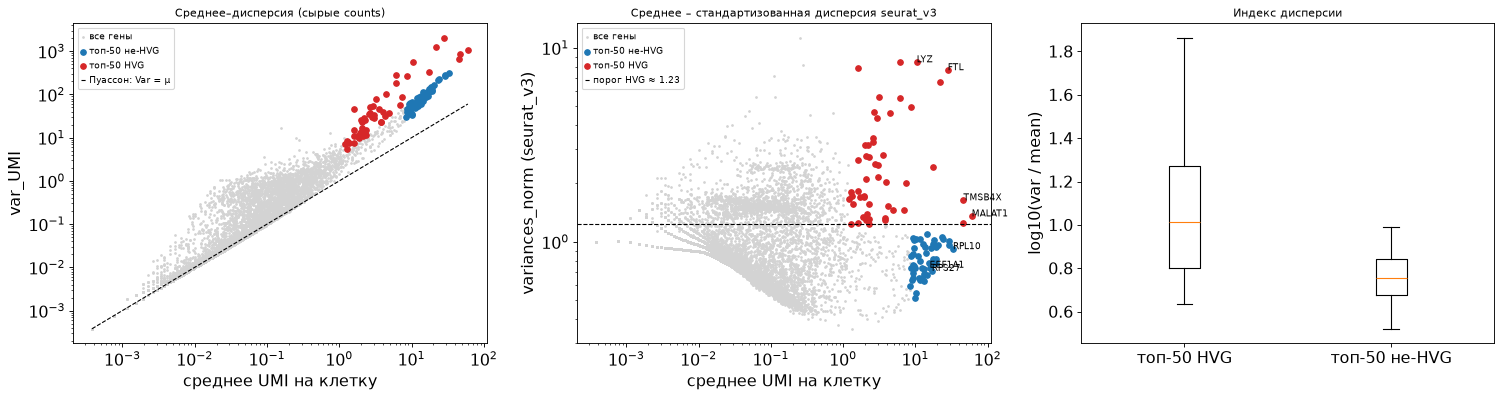

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
g = gene_stats[gene_stats["mean_UMI"] > 0]
for ax, (y, ttl) in zip(axes[:2], [("var_UMI", "Среднее–дисперсия (сырые counts)"),
                                   ("variances_norm (seurat_v3)", "Среднее – стандартизованная дисперсия seurat_v3")]):
    ax.scatter(g["mean_UMI"], g[y], s=2, c="lightgrey", label="все гены")
    ax.scatter(top_non["mean_UMI"], top_non[y], s=25, c="tab:blue", label="топ-50 не-HVG")
    ax.scatter(top_hvg["mean_UMI"], top_hvg[y], s=25, c="tab:red", label="топ-50 HVG")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("среднее UMI на клетку"); ax.set_ylabel(y)
    ax.set_title(ttl, fontsize=10); ax.grid(False)
x = np.geomspace(g["mean_UMI"].min(), g["mean_UMI"].max(), 200)
axes[0].plot(x, x, "k--", lw=1, label="Пуассон: Var = μ")
axes[1].axhline(thr, color="k", ls="--", lw=1, label=f"порог HVG ≈ {thr:.2f}")
for gname in ["MALAT1", "TMSB4X", "FTL", "LYZ", "RPL10", "RPS27", "EEF1A1"]:
    axes[1].annotate(gname, (g.loc[gname, "mean_UMI"], g.loc[gname, "variances_norm (seurat_v3)"]), fontsize=8)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)

data = [np.log10(top_hvg["var/mean"]), np.log10(top_non["var/mean"])]
axes[2].boxplot(data)
axes[2].set_xticks([1, 2], ["топ-50 HVG", "топ-50 не-HVG"])
axes[2].set_ylabel("log10(var / mean)"); axes[2].set_title("Индекс дисперсии", fontsize=10); axes[2].grid(False)
plt.tight_layout(); plt.show()

**Ответы**

**Обязательно ли HVG — самые экспрессируемые гены?** Нет. Среди 50 самых экспрессируемых генов вообще HVG всего 7. Медианный ранг HVG по средней экспрессии — около 3200 из 13 714. Метод `seurat_v3` выбирает гены, у которых дисперсия **больше ожидаемой при данном среднем**, а не гены с большим средним.

**Сравнение двух списков.**
- **Не-HVG из топ-50** экспрессируются в среднем даже сильнее: медиана ≈ 13 UMI на клетку против ≈ 2.6 у HVG. Их сырая дисперсия велика, но индекс дисперсии var/mean небольшой (≈ 6), а стандартизованная дисперсия ниже 1.1, то есть ниже порога отбора (≈ 1.23). Такие гены есть почти в каждой клетке (≈ 99%).
- **HVG из топ-50** — гены с var/mean до 50–70 (`FTL`, `FTH1`, `LYZ`). Многие из них экспрессируются только в части клеток (медиана ≈ 60%; `S100A9` — ≈ 36%, `GNLY` — ≈ 18%).

**Почему ген может иметь очень высокую экспрессию, но не попасть в HVG?** Его дисперсия целиком объясняется средним. Для отрицательного биномиального распределения $\mathrm{Var} = \mu + \mu^2/\theta$: чем больше среднее, тем больше и «нормальная» дисперсия. Рибосомные белки, `EEF1A1`, `TPT1`, `PTMA` одинаково высоко экспрессируются во всех клетках (housekeeping-гены). Колебания между клетками у них в основном технические: глубина и выборка UMI. Биологической разницы между типами клеток они почти не несут, поэтому стандартизованная дисперсия у них ≈ 1.

**Какие группы генов встречаются среди самых экспрессируемых?**
- **Не-HVG:** почти целиком (45 из 50) **рибосомные белки** RPL/RPS. Остальные — факторы трансляции (`EEF1A1`, `TPT1`), `MT-CO1`, `TMSB10`, `PTMA`. Это машина синтеза белка.
- **HVG:** гены, специфичные для типов клеток:
  - миелоидные: `LYZ`, `S100A8/9`, `CST3`, `TYROBP`, `FCER1G`, `LST1`, `AIF1`, `FCN1`;
  - **MHC II**: `CD74`, `HLA-DR/DP` (B-клетки, моноциты, DC);
  - цитотоксические: `NKG7`, `GNLY`, `CCL5`;
  - лимфоидные: `LTB`, `IL32`.
- Кроме того, в HVG попали очень высоко экспрессируемые «общие» гены: `MALAT1`, `TMSB4X`, `B2M`, `ACTB`, ферритины `FTL/FTH1`. У них `variances_norm` ≈ 1.25–1.6, то есть чуть выше порога. Их уровень всё же различается между популяциями: ферритины выше в моноцитах, `MALAT1` — в лимфоцитах.

---
## Задание 5. Влияние QC-метрик на PCA

Четыре сценария. Нормализация и логарифмирование во всех одинаковые, меняются только фильтрация и HVG.
QC-метрики уже посчитаны в `raw` до фильтрации, поэтому окраска доступна и для неотфильтрованных клеток.

1. без QC, без HVG     2700 клеток × 32738 генов, генов в PCA: 32738, доля дисп. PC1–4: [0.045 0.016 0.011 0.01 ]
2. без QC, с HVG       2700 клеток × 32738 генов, генов в PCA: 2000, доля дисп. PC1–4: [0.099 0.033 0.022 0.012]
3. с QC, без HVG       2638 клеток × 13714 генов, генов в PCA: 13714, доля дисп. PC1–4: [0.046 0.016 0.011 0.01 ]
4. с QC и HVG          2638 клеток × 13714 генов, генов в PCA: 2000, доля дисп. PC1–4: [0.1   0.033 0.023 0.012]


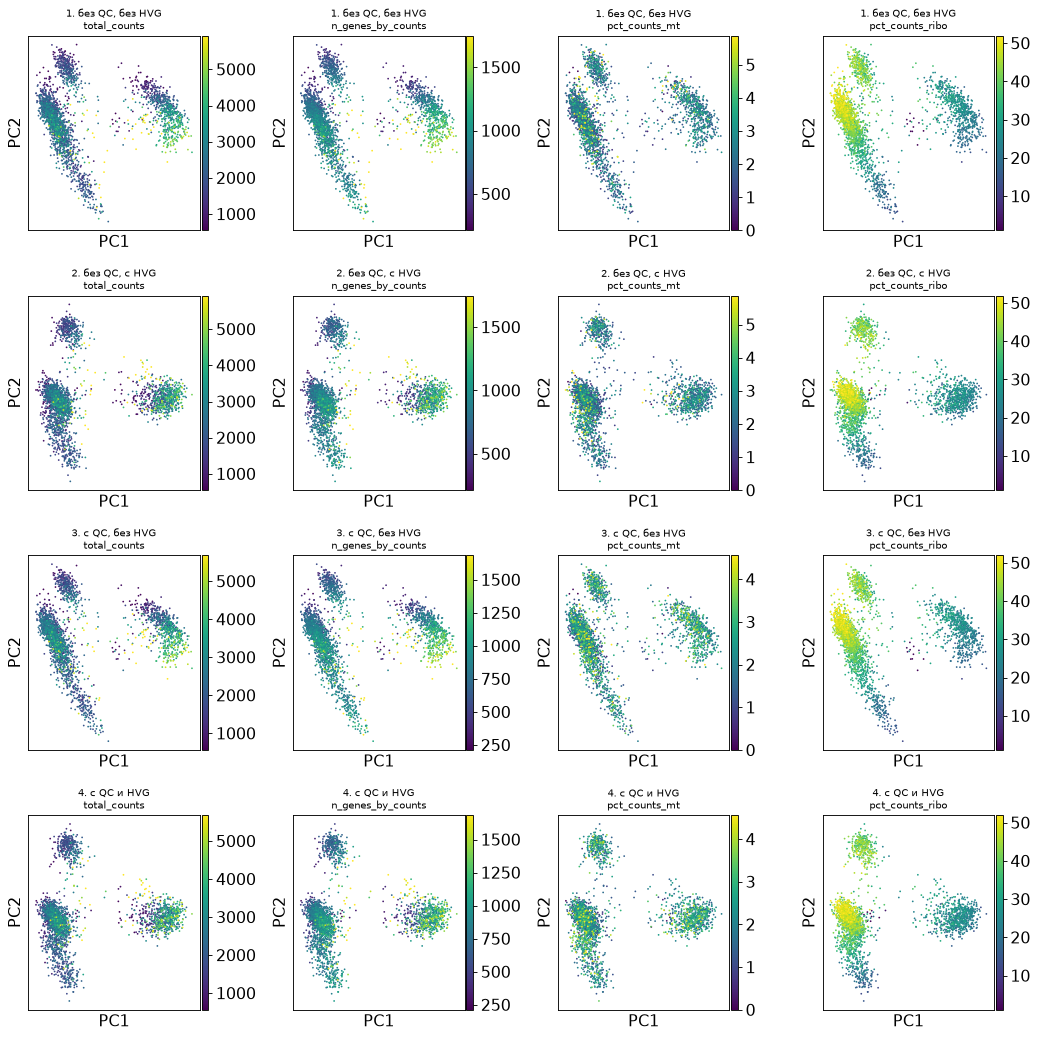

In [42]:
scenarios = {
    "1. без QC, без HVG": preprocess(raw, qc=False, hvg=False),
    "2. без QC, с HVG": preprocess(raw, qc=False, hvg=True),
    "3. с QC, без HVG": preprocess(raw, qc=True, hvg=False),
    "4. с QC и HVG": preprocess(raw, qc=True, hvg=True),
}
for a in scenarios.values():
    align_signs(a, adata)
for name, a in scenarios.items():
    print(f"{name:22s} {a.n_obs} клеток × {a.n_vars} генов, генов в PCA: "
          f"{int(a.var['highly_variable'].sum()) if 'highly_variable' in a.var else a.n_vars}, "
          f"доля дисп. PC1–4: {a.uns['pca']['variance_ratio'][:4].round(3)}")

QC_COLORS = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
pca_grid(scenarios, QC_COLORS, vmax="p99")

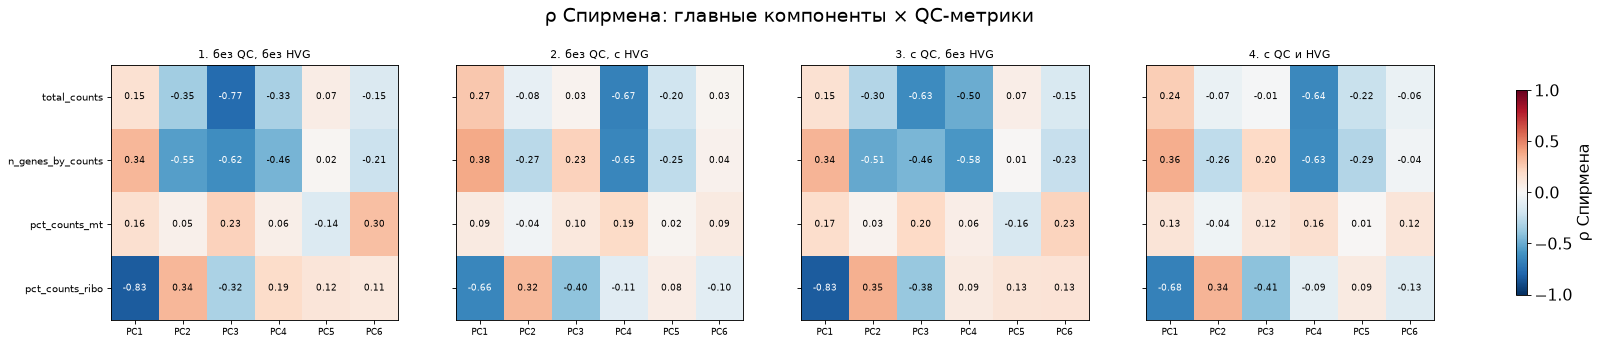

In [43]:
corr_heatmaps({name: pc_corr(a, QC_COLORS, 6) for name, a in scenarios.items()},
              "ρ Спирмена: главные компоненты × QC-метрики")

Scatter `total_counts` × `n_genes_by_counts`, цвет — `pct_counts_mt` (до и после фильтрации):

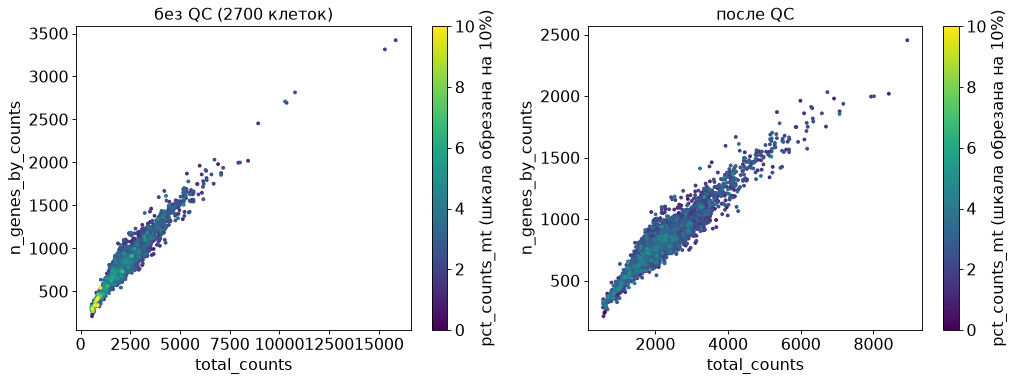

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, obs) in zip(axes, [("без QC (2700 клеток)", raw.obs), ("после QC", adata.obs)]):
    order = np.argsort(obs["pct_counts_mt"].values)
    s = ax.scatter(obs["total_counts"].values[order], obs["n_genes_by_counts"].values[order],
                   c=obs["pct_counts_mt"].values[order], s=6, cmap="viridis", vmax=10)
    plt.colorbar(s, ax=ax, label="pct_counts_mt (шкала обрезана на 10%)")
    ax.set(xlabel="total_counts", ylabel="n_genes_by_counts", title=name); ax.grid(False)
plt.tight_layout(); plt.show()

**Повтор без фильтрации, но с HVG (сценарий 2) подробнее.** Где на PCA оказываются клетки, которые QC бы удалил? Возьмём PC, сильнее всего связанную с глубиной, и посмотрим на неё вместе с PC1.

Сильнее всего с total_counts связана PC4 (ρ = -0.67)


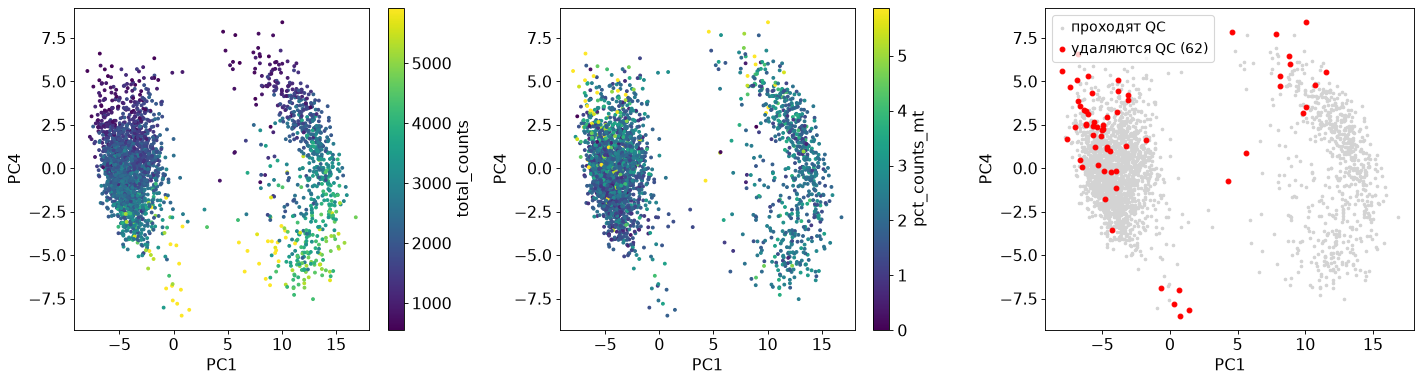

,PC1,PC2,PC3,PC4,PC5
медиана (проходят QC),-3.51,-0.47,-1.33,-0.02,-0.15
медиана (удаляются),-4.65,-0.52,-0.78,2.51,0.54
Q1 (проходят),-4.75,-1.80,-2.71,-1.66,-1.29
Q3 (проходят),6.80,0.75,2.66,1.50,1.01


,total_counts,n_genes_by_counts,pct_counts_mt
count,62.0,62.0,62.0
mean,2125.2,715.4,6.5
std,3237.0,710.3,3.3
min,548.0,267.0,1.8
25%,754.8,385.0,5.3
50%,1129.5,493.5,5.7
75%,1700.2,680.5,6.6
max,15844.0,3422.0,22.6


In [45]:
a2 = scenarios["2. без QC, с HVG"]
removed = ~a2.obs_names.isin(adata.obs_names)
rho = pc_corr(a2, ["total_counts"], 10).loc["total_counts"]
depth_pc = int(rho.abs().values.argmax())
print(f"Сильнее всего с total_counts связана PC{depth_pc + 1} (ρ = {rho.iloc[depth_pc]:.2f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
X2 = a2.obsm["X_pca"]
for ax, c, ttl in [(axes[0], a2.obs["total_counts"], "total_counts"),
                   (axes[1], a2.obs["pct_counts_mt"], "pct_counts_mt")]:
    s = ax.scatter(X2[:, 0], X2[:, depth_pc], c=c, s=6, cmap="viridis", vmax=np.percentile(c, 99))
    plt.colorbar(s, ax=ax, label=ttl)
ax = axes[2]
ax.scatter(X2[~removed, 0], X2[~removed, depth_pc], s=5, c="lightgrey", label="проходят QC")
ax.scatter(X2[removed, 0], X2[removed, depth_pc], s=18, c="red", label=f"удаляются QC ({removed.sum()})")
ax.legend()
for ax in axes:
    ax.set(xlabel="PC1", ylabel=f"PC{depth_pc + 1}"); ax.grid(False)
plt.tight_layout(); plt.show()

pos = pd.DataFrame({f"PC{k + 1}": [np.median(X2[~removed, k]), np.median(X2[removed, k]),
                                   np.percentile(X2[~removed, k], 25), np.percentile(X2[~removed, k], 75)]
                    for k in range(5)},
                   index=["медиана (проходят QC)", "медиана (удаляются)", "Q1 (проходят)", "Q3 (проходят)"])
display(pos.round(2))
display(a2.obs.loc[removed, ["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe().round(1))

**Ответы**

**Связано ли положение клеток на PCA с числом UMI?** Да, но не на первых двух компонентах. PC1 и PC2 — биологические оси (миелоидные/лимфоидные, B/NK), их корреляция с `total_counts` небольшая (|ρ| ≤ 0.3). Зато есть отдельная **«ось глубины»**:
- с HVG — **PC4**: ρ ≈ −0.64 с `total_counts` и ≈ −0.63 с `n_genes_by_counts` (сценарий 4), без QC ≈ −0.67;
- без HVG она поднимается на **PC3**: ρ ≈ −0.77 без QC и ≈ −0.63 с QC.

Нормализация на 10⁴ и log1p не убирают зависимость от глубины полностью: у клеток с большей библиотекой обнаружено больше слабо экспрессируемых генов, а лог-преобразование нулей и малых чисел нелинейно.

**Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов?** Выраженного нет. На PC1–PC5 |ρ| с `pct_counts_mt` во всех сценариях ≤ 0.23. Слабая «mt-ось» появляется только в сценарии 1 (без QC и без HVG): PC6 с ρ ≈ 0.30. То есть она возникает, когда повреждённые клетки остались в данных, а гены не отфильтрованы. Небольшой градиент идёт и вдоль PC1, у моноцитов mt% чуть выше, — это скорее биология. Клетки с mt > 5% в сценарии без QC — всего 2% клеток. Отдельной компоненты они не образуют, но смещены вдоль оси глубины (медиана PC4 ≈ 2.5 против ≈ 0 у остальных) — у них мало UMI. Гораздо сильнее с PC1 связана **доля рибосомных UMI**: ρ ≈ −0.68 с HVG, ≈ −0.83 без HVG. Это в основном биология (лимфоциты против моноцитов), но такая связь показывает, что без HVG в PC1 заметно «подмешиваются» рибосомные гены.

**Можно ли заподозрить влияние технических факторов на главные компоненты?** Да.
1. Одна из первых пяти PC (PC3 или PC4) почти целиком описывается глубиной секвенирования. А по умолчанию в граф соседей и UMAP идут первые 30 PC, то есть эта ось влияет и на кластеризацию.
2. Без QC «плохие» клетки (мало UMI и много мтДНК) уходят к краю этой оси и могут образовать ложный кластер. При бóльшей доле плохих клеток это было бы ещё заметнее.
3. Без HVG техническая ось поднимается выше по номеру и сильнее связана с глубиной.

Что можно сделать: фильтровать клетки по QC, отбирать HVG, использовать остатки Пирсона или `sctransform` вместо log1p, `sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"])` (с осторожностью), исключать техническую PC.

---
## Задание 6. Какие гены формируют главные компоненты?

`adata.varm["PCs"]` — матрица loadings (гены × компоненты). PCA строилась только по HVG, поэтому у остальных генов loadings равны нулю, и их отбрасываем.

In [46]:
loadings = pd.DataFrame(adata.varm["PCs"][:, :2], index=adata.var_names, columns=["PC1", "PC2"])
loadings = loadings[adata.var["highly_variable"].values]

top_tab = {}
for pc in ["PC1", "PC2"]:
    pos_, neg_ = loadings[pc].nlargest(10), loadings[pc].nsmallest(10)
    top_tab[(pc, "+ ген")] = pos_.index
    top_tab[(pc, "+ loading")] = pos_.values
    top_tab[(pc, "− ген")] = neg_.index
    top_tab[(pc, "− loading")] = neg_.values
top_tab = pd.DataFrame(top_tab, index=range(1, 11))
display(top_tab.round(3))

PC1                                   PC2                            
     + ген + loading   − ген − loading     + ген + loading   − ген − loading
1      LYZ     0.220     LTB    -0.113   HLA-DRA     0.268    NKG7    -0.216
2     CST3     0.212    IL32    -0.106      CD74     0.210  S100A4    -0.181
3   S100A9     0.211  MALAT1    -0.067  HLA-DPB1     0.198    CCL5    -0.165
4   TYROBP     0.199    IL7R    -0.059  HLA-DRB1     0.193    IL32    -0.145
5   S100A8     0.171    CCL5    -0.051     CD79A     0.184    GNLY    -0.134
6   LGALS1     0.168     CD2    -0.046  HLA-DPA1     0.180    CTSW    -0.134
7     AIF1     0.166    CTSW    -0.044  HLA-DQA1     0.169    GZMA    -0.134
8     LST1     0.166  STK17A    -0.038  HLA-DQB1     0.161    CST7    -0.131
9   FCER1G     0.156   ACAP1    -0.036     CD79B     0.158    SRGN    -0.123
10    FCN1     0.151   CD247    -0.036  HLA-DRB5     0.142   ANXA1    -0.120

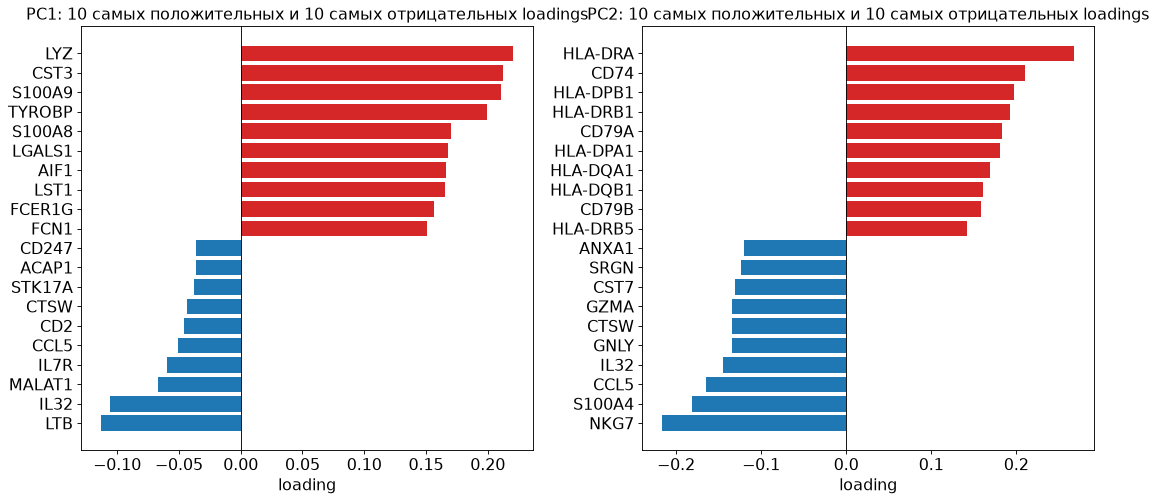

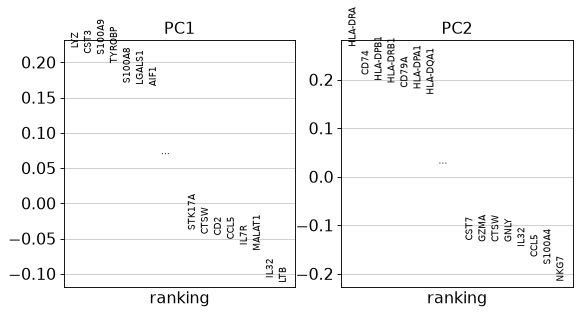

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    sel = pd.concat([loadings[pc].nsmallest(10), loadings[pc].nlargest(10).iloc[::-1]])
    ax.barh(range(len(sel)), sel.values, color=np.where(sel.values > 0, "tab:red", "tab:blue"))
    ax.set_yticks(range(len(sel)), sel.index)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{pc}: 10 самых положительных и 10 самых отрицательных loadings")
    ax.set_xlabel("loading"); ax.grid(False)
plt.tight_layout(); plt.show()

sc.pl.pca_loadings(adata, components="1,2", include_lowest=True, n_points=15)

['LYZ', 'CST3', 'LTB', 'IL32', 'HLA-DRA', 'CD74', 'NKG7', 'S100A4']


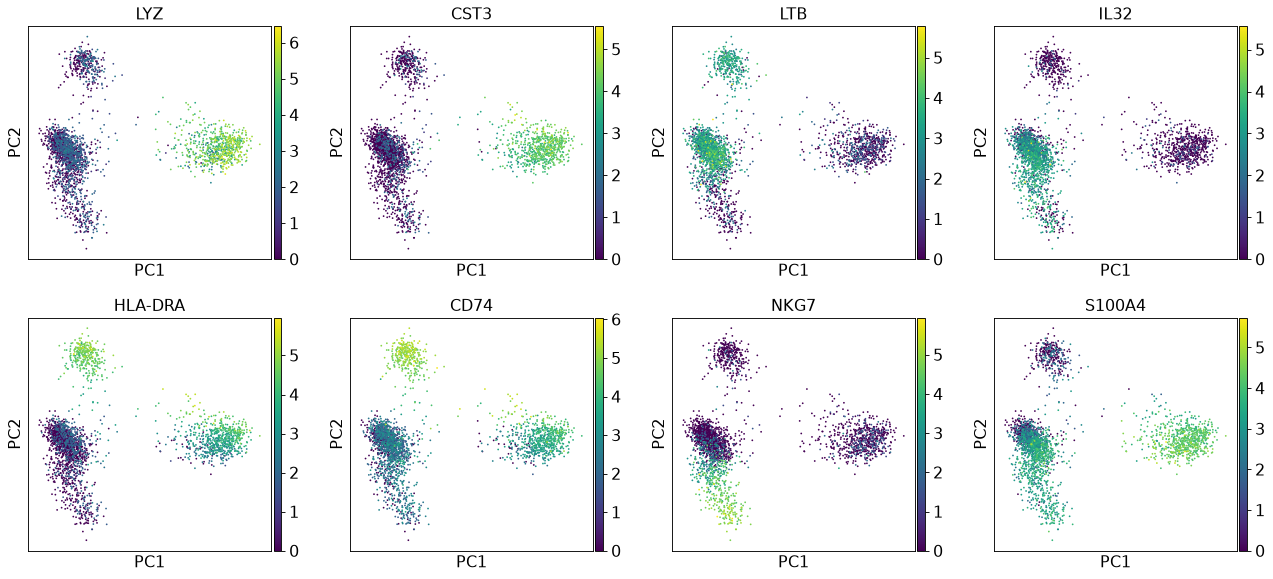

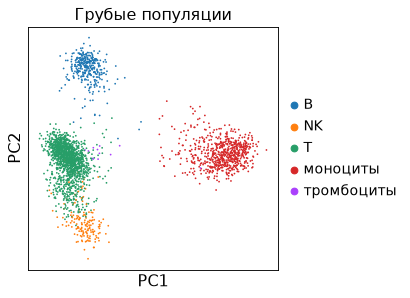

In [48]:
# Экспрессия найденных генов на PCA: по 2 гена с каждого «полюса» PC1 и PC2
genes_to_show = (list(loadings["PC1"].nlargest(2).index) + list(loadings["PC1"].nsmallest(2).index) +
                 list(loadings["PC2"].nlargest(2).index) + list(loadings["PC2"].nsmallest(2).index))
print(genes_to_show)
sc.pl.pca(adata, color=genes_to_show, ncols=4, size=10)
sc.pl.pca(adata, color="rough_type", size=10, title="Грубые популяции")

In [49]:
# Связь PC1/PC2 с QC и клеточным циклом
top_genes = set(top_tab[("PC1", "+ ген")]) | set(top_tab[("PC1", "− ген")]) | \
            set(top_tab[("PC2", "+ ген")]) | set(top_tab[("PC2", "− ген")])
print("Среди 40 топ-генов: мтДНК —", sum(adata.var.loc[list(top_genes), "mt"]),
      "| рибосомные —", sum(adata.var.loc[list(top_genes), "ribo"]),
      "| гены клеточного цикла —", len(top_genes & set(S_GENES + G2M_GENES)))
display(pc_corr(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"], 5).round(2))

Среди 40 топ-генов: мтДНК — 0 | рибосомные — 0 | гены клеточного цикла — 0


,PC1,PC2,PC3,PC4,PC5
total_counts,0.24,-0.07,-0.01,-0.64,-0.22
n_genes_by_counts,0.36,-0.26,0.20,-0.63,-0.29
pct_counts_mt,0.13,-0.04,0.12,0.16,0.01
pct_counts_ribo,-0.68,0.34,-0.41,-0.09,0.09


**Ответы**

**Какие гены сильнее всего определяют PC1 и PC2?**
- **PC1, положительный полюс:** `LYZ`, `CST3`, `S100A9`, `S100A8`, `TYROBP`, `LGALS1`, `AIF1`, `LST1`, `FCER1G`, `FCN1` — программа **моноцитов и миелоидных клеток**.
- **PC1, отрицательный полюс:** `LTB`, `IL32`, `MALAT1`, `IL7R`, `CCL5`, `CD2`, `CTSW`, `CD247`, `STK17A`, `ACAP1` — **T-лимфоциты** и лимфоциты в целом.
- **PC2, положительный полюс:** `HLA-DRA`, `CD74`, `HLA-DPB1`, `HLA-DRB1`, `HLA-DPA1`, `HLA-DQA1/DQB1`, `CD79A`, `CD79B` — **MHC II и B-клетки** (антигенпрезентирующие).
- **PC2, отрицательный полюс:** `NKG7`, `GNLY`, `GZMA`, `CST7`, `CTSW`, `CCL5`, `S100A4`, `IL32`, `SRGN`, `ANXA1` — **цитотоксические NK и CD8 T-клетки**.

Знак loadings произволен: в другой версии библиотеки «+» и «−» могут поменяться местами, но пары генов останутся теми же.

**Связаны ли они с иммунными популяциями, клеточным циклом или QC?** С **иммунными популяциями** — однозначно, это классические маркеры из туториалов Seurat и Scanpy для PBMC 3k. Генов клеточного цикла среди топ-генов нет (см. дополнительное задание), генов мтДНК и рибосомных тоже нет: они не попали в HVG. Косвенная связь с QC есть: PC1 коррелирует с долей рибосомных UMI (ρ ≈ −0.68). Это не технический артефакт, а свойство популяций: у лимфоцитов рибосомных транскриптов больше, у моноцитов меньше.

**Можно ли биологически интерпретировать PC по этим генам?** Для PC1 и PC2 — да: «миелоидные ↔ лимфоидные» и «B/APC ↔ цитотоксические NK/CD8». Но с оговорками:
1. PC — линейная комбинация **всех** HVG, топ-10 описывают её лишь частично.
2. Одна компонента может смешивать несколько биологических осей. PC2 противопоставляет B-клетки NK, но частично захватывает и моноциты, потому что у них тоже высокий MHC II.
3. Более поздние компоненты интерпретировать сложнее, и часть из них техническая: PC4 связана с глубиной (задание 5).
4. PCA ищет оси максимальной дисперсии, а не биологически «чистые» оси. Редкие популяции (DC, тромбоциты) на первых PC почти не видны.

---
## Задание 7. Нормализация, логарифмирование и стандартизация

Все варианты — после QC и на одном наборе HVG (`seurat_v3` считается по сырым counts и от нормализации не зависит). Кроме вариантов из условия добавлены «log1p без normalize» (чтобы разделить вклад двух шагов) и `scale(max_value=10)` — так обычно делают в туториалах. Для окраски берём лог-нормированную экспрессию из `adata`, чтобы цвета были сопоставимы между строками.

In [ ]:
variants = {
    "counts (без normalize и log1p)": dict(normalize=False, log=False),
    "normalize, без log1p": dict(normalize=True, log=False),
    "log1p, без normalize": dict(normalize=False, log=True),
    "normalize + log1p (семинар)": dict(),
    "normalize + log1p + scale": dict(scale=True),
    "normalize + log1p + scale(max=10)": dict(scale=True, scale_max=10),
}
pca_norm = {name: preprocess(raw, **kw) for name, kw in variants.items()}
for a in pca_norm.values():
    align_signs(a, adata)

pca_grid(pca_norm, MARKER_GENES + ["total_counts"], expr_from=adata, vmax="p99")

In [ ]:
rows = {}
for name, a in pca_norm.items():
    add_leiden(a, key="leiden_norm")
    hv = a.var["highly_variable"].values
    v = gene_variances(a.X[:, hv])
    pc1 = pd.Series(a.varm["PCs"][hv, 0], index=a.var_names[hv])
    rho = pc_corr(a, ["total_counts"], 5).loc["total_counts"]
    rows[name] = {
        "доля дисп. PC1": a.uns["pca"]["variance_ratio"][0],
        "доля дисп. PC2": a.uns["pca"]["variance_ratio"][1],
        "доля дисперсии HVG у топ-10 генов": np.sort(v)[::-1][:10].sum() / v.sum(),
        "ρ(PC1, total_counts)": rho["PC1"],
        "ρ(PC2, total_counts)": rho["PC2"],
        "max |ρ| PC1–5 с total_counts": rho.abs().max(),
        "ARI Leiden vs семинар": adjusted_rand_score(adata.obs["leiden"], a.obs["leiden_norm"]),
        "число кластеров": a.obs["leiden_norm"].nunique(),
        "топ-5 генов PC1 (|loading|)": ", ".join(pc1.abs().nlargest(5).index),
        "топ-5 генов PC2 (|loading|)": ", ".join(
            pd.Series(a.varm["PCs"][hv, 1], index=a.var_names[hv]).abs().nlargest(5).index),
    }
norm_table = pd.DataFrame(rows).T
with pd.option_context("display.max_colwidth", 60):
    display(norm_table.round(3))

corr_heatmaps({k: pc_corr(a, ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"], 5)
               for k, a in list(pca_norm.items())[:4]}, "ρ Спирмена: PC × QC-метрики")

**Ответы**

Как читать таблицу: «ARI vs семинар» — согласие кластеров Leiden с эталоном (1 = полное совпадение); «доля дисперсии у топ-10 генов» — насколько PCA «захвачен» несколькими генами.

**Что сильнее влияет на PCA — нормализация или логарифмирование?** Логарифмирование.
- Без log1p (сырые counts или только normalize) PC1 объясняет 39–44% дисперсии. На 10 генов приходится 69–75% всей дисперсии HVG (после log1p — 5–10%). Компоненты определяются горсткой самых экспрессируемых генов (`FTL`, `FTH1`, `MALAT1`, `TMSB4X`, `B2M`, `ACTB`), потому что дисперсия counts растёт примерно как квадрат среднего. На картинке это вытянутые «лучи» вместо облаков.
- Структура популяций при этом сильно искажена: ARI с эталоном ≈ 0.40–0.46.
- log1p без нормализации даёт уже правильные гены на PC1 и PC2 (`LYZ`, `CST3`, `HLA-DRA`, `NKG7`) и ARI ≈ 0.63. Но PC1 коррелирует с `total_counts` (ρ ≈ 0.50) и `n_genes` (ρ ≈ 0.59): без нормализации первая ось смешивает биологию с глубиной секвенирования.
- Тонкость: в варианте «normalize без log1p» связь с глубиной самая слабая (max |ρ| ≈ 0.27), а после log1p ось глубины снова появляется на PC4 (|ρ| ≈ 0.64). Логарифм нелинейно сжимает малые значения, а у клеток с маленькой библиотекой больше нулей среди слабых генов. Это известный недостаток схемы «log1p(CP10k)», и его исправляют остатки Пирсона и `sctransform`.

**Что даёт каждая процедура?**
- **`normalize_total`** убирает различия в размере библиотеки (захват, глубина): на сырых counts клетка с вдвое большим числом UMI выглядит «вдвое сильнее» по всем генам. Без неё технический фактор попадает в главные компоненты.
- **`log1p`** стабилизирует дисперсию (для NB-данных дисперсия ∝ μ + μ²/θ), переводит мультипликативные различия в аддитивные (кратность изменения) и не даёт нескольким генам с огромным средним доминировать.
- **`scale`** приводит каждый ген к среднему 0 и дисперсии 1, так что все HVG получают одинаковый вес в PCA. Это усиливает слабые, но специфичные гены. Обратная сторона: шум слабых генов тоже усиливается, а редкие популяции получают огромные z-оценки. Без ограничения (`max_value=None`) PC2 целиком «захватывают» гены тромбоцитов (`PTCRA`, `GP9`, `SDPR`, `GNG11`, `PF4`): у 12 клеток z-оценки достигают десятков, и на картинке PC1–PC2 все остальные клетки сжаты в полосу. С `max_value=10` PC2 снова описывает цитотоксические клетки (`NKG7`, `PRF1`, `CST7`, `GZMB`, `GZMA`).

**Сильно ли помогает scale?** Здесь — нет. С `max_value=10` картинка близка к эталонной, кластеры согласуются хорошо (ARI ≈ 0.87). Но каждая компонента объясняет меньшую долю дисперсии (PC1 ≈ 3% против 10%), а при том же `resolution` кластеров меньше: 7, без обрезки — 5, против 8. Без обрезки scale даже вредит (см. PC2). Scale меняет «веса» генов, а не исправляет технику: связь PC с глубиной остаётся (max |ρ| ≈ 0.65). В Seurat стандартизация — стандартный шаг (`ScaleData`), в Scanpy — по желанию.

**Все ли процедуры нужно делать перед PCA?**
- **Нормализация и логарифмирование (или их замены) — да.** Альтернативы: остатки Пирсона (`sc.experimental.pp.normalize_pearson_residuals`) или `sctransform` решают обе задачи сразу, и scale после них не нужен.
- **Scale — по желанию.** Если делать, то с `max_value` (обычно 10), и смотреть, не захватывают ли первые PC редкие популяции или шумные гены.

---
## Дополнительное задание. Клеточный цикл и PCA

`sc.tl.score_genes_cell_cycle` для каждой клетки считает:

$$\text{score} = \overline{\text{экспрессия генов фазы}} - \overline{\text{экспрессия контрольных генов}},$$

где контрольные гены случайно выбираются из тех же бинов по средней экспрессии. Фазу S или G2M клетке присваивают, если соответствующая оценка больше нуля и больше второй оценки, иначе — G1.
Оценки считаются по лог-нормированной матрице **всех** генов.

In [ ]:
s_genes = [g for g in S_GENES if g in adata.var_names]
g2m_genes = [g for g in G2M_GENES if g in adata.var_names]
print(f"S: {len(s_genes)}/{len(S_GENES)}, G2M: {len(g2m_genes)}/{len(G2M_GENES)} генов есть в данных")
print("Отсутствуют (отфильтрованы min_cells=3, т.е. почти не экспрессируются):",
      sorted(set(S_GENES + G2M_GENES) - set(s_genes + g2m_genes)))

sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes, random_state=SEED)
display(adata.obs["phase"].value_counts().to_frame("клеток"))
adata.obs[["S_score", "G2M_score"]].describe().round(3)

In [ ]:
sc.pl.pca(adata, color=["S_score", "G2M_score", "phase"], size=12, ncols=3, color_map="viridis")
sc.pl.pca(adata, color=["MKI67", "TOP2A", "PCNA", "rough_type"], size=12, ncols=4)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ph, col in zip(["G1", "S", "G2M"], ["lightgrey", "tab:blue", "tab:red"]):
    m = adata.obs["phase"] == ph
    axes[0].scatter(adata.obs.loc[m, "S_score"], adata.obs.loc[m, "G2M_score"], s=6, c=col, label=f"{ph} ({m.sum()})")
axes[0].axhline(0, color="k", lw=0.6); axes[0].axvline(0, color="k", lw=0.6)
axes[0].plot([-0.2, 0.8], [-0.2, 0.8], "k:", lw=0.6)
axes[0].set(xlabel="S_score", ylabel="G2M_score", title="Оценки фаз"); axes[0].legend(); axes[0].grid(False)

cc_corr = pc_corr(adata, ["S_score", "G2M_score"], 10)
cc_corr.T.plot.bar(ax=axes[1])
axes[1].set(ylabel="ρ Спирмена", title="Корреляция оценок цикла с PC1–PC10"); axes[1].axhline(0, color="k", lw=0.6)
axes[1].grid(False)
plt.tight_layout(); plt.show()
display(cc_corr.round(2))

score_max = adata.obs[["S_score", "G2M_score"]].max(axis=1)
print("Клеток с max(S, G2M) > порога:", {t: int((score_max > t).sum()) for t in [0.1, 0.2, 0.3, 0.5]})
for g in ["MKI67", "TOP2A", "PCNA", "TYMS"]:
    print(f"{g}: обнаружен в {(adata[:, g].X > 0).sum()} клетках")
lym = adata.obs["rough_type"].isin(["T", "B", "NK"]).values
mono = (adata.obs["rough_type"] == "моноциты").values
e = sc.get.obs_df(adata, keys=s_genes)
drivers = pd.DataFrame({"Δ средней экспрессии (лимфоциты − моноциты)": e[lym].mean() - e[mono].mean(),
                        "% клеток с UMI: лимфоциты": 100 * (e[lym] > 0).mean(),
                        "% клеток с UMI: моноциты": 100 * (e[mono] > 0).mean()})
print("\nS-гены, сильнее всего различающиеся между лимфоцитами и моноцитами:")
display(drivers.sort_values(drivers.columns[0], ascending=False).head(5).round(2))
print("\nДоля фаз внутри грубых популяций:")
display(pd.crosstab(adata.obs["rough_type"], adata.obs["phase"], normalize="index").round(2))

**Ответы**

**Разделяются ли клетки по фазам клеточного цикла?** Нет. PBMC — в основном покоящиеся дифференцированные клетки.
- Оценки у подавляющего большинства клеток около нуля: медиана S ≈ −0.02, G2M ≈ −0.09.
- Действительно делящихся клеток единицы: max(S, G2M) > 0.3 только у 5 клеток, > 0.2 — у 9. `MKI67` обнаружен в 8 клетках, `TOP2A` — в 5.
- Формально в «S» попали около трети клеток. Но это **артефакт правила присвоения фазы**: клетка получает S, как только S_score > 0 и больше G2M_score, даже если оценка 0.01, то есть в пределах шума. На PCA «фазы» раскиданы по всем популяциям и отдельных групп не образуют. Ось клеточного цикла в этих данных — не основной источник дисперсии.

**Есть ли связь клеточного цикла с PC1 или PC2?** Практически нет: |ρ| для G2M_score ≤ 0.07 на всех PC1–10. Для S_score заметна только слабая связь с PC1 (ρ ≈ −0.23). Но это эффект состава популяций, а не деления. В лимфоцитах доля формальных «S» около 40%, в моноцитах около 14%. Главный вклад даёт один ген набора — `RPA2` (субъединица белка репликации A, участвует и в репарации): его UMI есть у ≈ 22% лимфоцитов и только у ≈ 8% моноцитов, см. таблицу выше. Контрольные гены подбираются только по уровню экспрессии, поэтому такие различия между популяциями превращаются в «S-фазу». Генов клеточного цикла среди топ-loadings PC1/PC2 нет (задание 6).

**Почему клетки одного типа могут отличаться по экспрессии генов цикла?**
1. Деление асинхронно: в любой момент клетки популяции находятся в разных фазах. Пример — пролиферирующие активированные T-клетки, плазмабласты, клетки в ответе на антиген.
2. Внутри типа есть состояния: покоящиеся наивные клетки против активированных или клетки памяти после клональной экспансии.
3. Гены S-фазы — это в том числе гены репарации и синтеза ДНК, которые могут меняться и вне деления.
4. Технический шум: при ~2000 UMI на клетку большинство генов цикла детектируется в единичных клетках, поэтому оценки шумные.

В пролиферирующих тканях (костный мозг, опухоли, эмбрионы) ось цикла бывает одной из главных. Тогда её учитывают: `sc.pp.regress_out(adata, ["S_score", "G2M_score"])` или регрессия разности `S_score − G2M_score`, чтобы сохранить различие «делящиеся / неделящиеся».